# Old34 team-feedback deep dives — 2026-09-17

**Purpose.** Turn three observations from the D1a all-representation heatmap review into plots that can be checked, not restated. The notebook is a companion to `stage2_old34_d1a_descriptive_deep_dives_20260910.ipynb` (taxonomy, patient maps, PCA/FA variance for three focus panels) and `stage2_old34_meeting_followup_metric_interactions.ipynb` D8 (IFN-α PCA40 vs FA40 attribution).

**Experiment.** `20260525_060508_stage0_mrd_old34_broad_screen_82db5093`

**What this notebook adds**

1. **Observation 1 — K and HVGs.** Median-lift vs independently fitted K for knowledge panels vs HVGs, plus **knee / scree plots for every Stage 1 method × K** on the panels the discussion named. Orthogonality is checked on loadings and on scores, not assumed from method names.
2. **Observation 2 — DR ≫ direct genes.** Patient-by-patient lift for allograft rejection, apoptosis, and interferon-α, then the **Stage 2-selected factors** and their **top loading genes** (including LCK / ZAP70 and overlap with TNF / cytokine sets).
3. **Observation 3 — PCA40 vs FA40 on IFN-α.** Cross-method factor matching, within-method score collinearity, stored L1 coefficients for all seven supported patients, a local L1/L2/elastic-net refit on stored scores, and a written verdict on whether loadings can be read biologically.

**Scope.** Read-only over completed Stage 0/1 artifacts, the D1 atlas, and the Layer 4–5 selected-LOPO coefficient cache. The only new fits are small fold-wise logistics on **already stored** IFN-α K=40 scores, used to test Ankit’s L1-vs-L2 collinearity claim. No Stage 0/1/2 grid is rerun.

**Claim boundary.** Independently fitted K are not nested prefixes. Stage 1 is transductive. The displayed regularizer was selected on the same LOPO folds. Sign-agnostic bases plus sparse Stage 2 selection mean a loading is a hypothesis about an axis, not a unique gene program.


## 0. Setup

Outputs are namespaced under `feedback_deep_dive_20260917` so they do not overwrite D1a or D8 figures.


In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.optimize import linear_sum_assignment
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_rows", 80)

EXPERIMENT_ID = "20260525_060508_stage0_mrd_old34_broad_screen_82db5093"
INPUT_H5AD = Path("/home/minhang/mds_project/data/cohort_adata/adata_cellType_cnLabel_pseudoTime_collectionTime.h5ad")


def find_repo_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "experiments").exists():
            return candidate
    fallback = Path("/home/minhang/mds_project/sc_classification")
    if fallback.exists():
        return fallback
    raise FileNotFoundError("Could not locate sc_classification repository root")


REPO_ROOT = find_repo_root()
EXP_DIR = REPO_ROOT / "experiments" / EXPERIMENT_ID
BASE_DIAGNOSTIC_DIR = EXP_DIR / "analysis" / "scorecards" / "stage2_diagnostic"
TABLE_DIR = BASE_DIAGNOSTIC_DIR / "feedback_deep_dive_20260917"
FIGURE_DIR = EXP_DIR / "analysis" / "figures" / "stage2_diagnostic" / "feedback_deep_dive_20260917"
CACHE_DIR = EXP_DIR / "analysis" / "cache" / "stage2_diagnostic" / "feedback_deep_dive_20260917"
for directory in (TABLE_DIR, FIGURE_DIR, CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SOURCE_PATHS = {
    "atlas_representation": BASE_DIAGNOSTIC_DIR / "old34_d1_atlas_representation_table.csv",
    "atlas_patient": BASE_DIAGNOSTIC_DIR / "old34_d1_atlas_supported_patient_metrics.csv",
    "d1e_selection": BASE_DIAGNOSTIC_DIR / "old34_d1e_best_dr_vs_direct_gene_selection.csv",
    "representation_table": BASE_DIAGNOSTIC_DIR / "old34_representation_diagnostic_table.csv",
    "selected_lopo_coefficients": EXP_DIR / "analysis" / "cache" / "stage2_diagnostic" / "layer4_5" / "selected_lopo_coefficients.pkl.gz",
    "input_h5ad": INPUT_H5AD,
}
missing = [str(path) for name, path in SOURCE_PATHS.items() if name != "input_h5ad" and not path.exists()]
assert not missing, f"Missing required completed artifacts: {missing}"
assert SOURCE_PATHS["input_h5ad"].exists(), SOURCE_PATHS["input_h5ad"]

GENERATED_FIGURES: list[Path] = []
GENERATED_TABLES: list[Path] = []

METHOD_ORDER = ["pca", "fa", "factosig", "factosig_promax"]
METHOD_LABEL = {
    "pca": "PCA",
    "fa": "FA (sklearn, no rotation)",
    "factosig": "FactoSig varimax",
    "factosig_promax": "FactoSig promax",
}
K_ORDER = [5, 10, 20, 40]
CONFIG_ORDER = ["direct_gene"] + [f"{method}|K={k}" for method in METHOD_ORDER for k in K_ORDER]
SUPPORTED_PATIENTS = ["P01", "P02", "P03", "P04", "P06", "P07", "P09"]
ALLO_PANEL = "single_geneset__hallmark_allograft_rejection"
APOP_PANEL = "single_geneset__hallmark_apoptosis"
IFNA_PANEL = "single_geneset__hallmark_interferon_alpha_response"
TNF_PANEL = "single_geneset__hallmark_tnfa_signaling_via_nfkb"
IL6_PANEL = "single_geneset__hallmark_il6_jak_stat3_signaling"
IFNG_PANEL = "single_geneset__hallmark_interferon_gamma_response"
HVG_PANELS = {
    "hvg_top_requested_500__available_500": "HVG 500",
    "hvg_top_requested_1000__available_1000": "HVG 1,000",
    "hvg_top_requested_3000__available_3000": "HVG 3,000",
    "hvg_top_requested_10000__available_10000": "HVG 10,000",
}
FOCUS_PANELS = {
    ALLO_PANEL: "Allograft rejection",
    APOP_PANEL: "Apoptosis",
    IFNA_PANEL: "Interferon-α response",
}
KNEE_PANELS = {
    **{pid: label for pid, label in HVG_PANELS.items()},
    **FOCUS_PANELS,
}
HIGHLIGHT_GENES = ["LCK", "ZAP70", "CD3D", "CD3E", "CD3G", "TNF", "STAT1", "IFI27", "TXNIP"]


def save_figure(fig: plt.Figure, stem: str, *, dpi: int = 180) -> Path:
    png = FIGURE_DIR / f"{stem}.png"
    fig.savefig(png, dpi=dpi, bbox_inches="tight")
    fig.savefig(png.with_suffix(".pdf"), bbox_inches="tight")
    GENERATED_FIGURES.extend([png, png.with_suffix(".pdf")])
    print(png)
    return png


def write_csv(frame: pd.DataFrame, filename: str, *, index: bool = False) -> Path:
    path = TABLE_DIR / filename
    frame.to_csv(path, index=index)
    GENERATED_TABLES.append(path)
    print(path)
    return path


def stage1_dir(panel_id: str, method: str, k: int, seed: int = 42) -> Path:
    return EXP_DIR / "stage1_dr" / f"panel_id={panel_id}" / f"method={method}" / f"k={k}" / f"seed={seed}"


def load_panel_genes(panel_id: str) -> list[str]:
    path = EXP_DIR / "preprocessing" / "panels" / "stage0_panel_genes" / f"{panel_id}.json"
    payload = json.loads(path.read_text())
    return list(payload["genes"]) if isinstance(payload, dict) and "genes" in payload else list(payload)


def load_diagnostics(panel_id: str, method: str, k: int) -> dict:
    path = stage1_dir(panel_id, method, k) / "diagnostics.json"
    return json.loads(path.read_text()) if path.exists() else {}


def load_stage1(panel_id: str, method: str, k: int = 40) -> dict:
    directory = stage1_dir(panel_id, method, k)
    scores = np.load(directory / "scores.npy")
    loadings = np.load(directory / "loadings.npy")
    genes = load_panel_genes(panel_id)
    if loadings.shape[0] != len(genes) and loadings.shape[1] == len(genes):
        loadings = loadings.T
    assert scores.shape[1] == int(k), (scores.shape, k)
    assert loadings.shape == (len(genes), int(k)), (loadings.shape, len(genes), k)
    return {
        "scores": np.asarray(scores, dtype=float),
        "loadings": np.asarray(loadings, dtype=float),
        "genes": genes,
        "diagnostics": load_diagnostics(panel_id, method, k),
    }


def zscore_columns(matrix: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    means = matrix.mean(axis=0)
    stds = matrix.std(axis=0)
    nondegenerate = stds > 1e-12
    z = (matrix - means) / np.where(nondegenerate, stds, 1.0)
    z[:, ~nondegenerate] = 0.0
    return z, nondegenerate


def score_correlation(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    za, _ = zscore_columns(a)
    zb, _ = zscore_columns(b)
    return (za.T @ zb) / len(za)


def component_energy(method: str, diagnostics: dict, n_genes: int) -> dict[str, np.ndarray]:
    """Per-component energy. PCA uses true explained-variance ratio; others use loading energy."""
    loading_ss = np.asarray(diagnostics.get("loading_ss", []), dtype=float)
    score_var = np.asarray(diagnostics.get("score_variance", []), dtype=float)
    extras = diagnostics.get("extras", {}).get("uns", {})
    empty = {
        "per_component": np.array([]),
        "cumulative": np.array([]),
        "metric": "unavailable",
        "relative": np.array([]),
        "captured_fraction": np.nan,
        "captured_label": "",
        "is_variance_fraction": False,
        "score_variance": score_var,
    }
    if method == "pca" and "explained_variance_ratio" in extras:
        evr = np.asarray(extras["explained_variance_ratio"], dtype=float)
        captured = float(evr.sum()) if evr.size else np.nan
        return {
            "per_component": evr,
            "cumulative": np.cumsum(evr),
            "metric": "PCA total-variance fraction",
            "relative": evr / evr.sum() if evr.sum() else evr,
            "captured_fraction": captured,
            "captured_label": f"{100 * captured:.0f}% of gene variance",
            "is_variance_fraction": True,
            "score_variance": score_var,
        }
    if loading_ss.size == 0:
        return empty
    relative = loading_ss / loading_ss.sum()
    common_fraction = loading_ss / float(n_genes) if n_genes else relative
    if method == "factosig_promax":
        return {
            "per_component": relative,
            "cumulative": np.cumsum(relative),
            "metric": "relative loading energy (promax scale is not a variance fraction)",
            "relative": relative,
            "captured_fraction": np.nan,
            "captured_label": "not a variance %",
            "is_variance_fraction": False,
            "score_variance": score_var,
        }
    if method in {"fa", "factosig"}:
        captured = float(common_fraction.sum()) if common_fraction.size else np.nan
        return {
            "per_component": common_fraction,
            "cumulative": np.cumsum(common_fraction),
            "metric": "loading energy / n_genes (common-variance proxy, not PCA EVR)",
            "relative": relative,
            "captured_fraction": captured,
            "captured_label": f"{100 * captured:.0f}% common-var. proxy",
            "is_variance_fraction": True,
            "score_variance": score_var,
        }
    return {
        "per_component": relative,
        "cumulative": np.cumsum(relative),
        "metric": "relative loading energy",
        "relative": relative,
        "captured_fraction": np.nan,
        "captured_label": "not a variance %",
        "is_variance_fraction": False,
        "score_variance": score_var,
    }


def configuration_label(method: str, k: int) -> str:
    return f"{method}|K={int(k)}"


print("Repository:", REPO_ROOT)
print("Experiment:", EXP_DIR)
print("Tables:", TABLE_DIR)
print("Figures:", FIGURE_DIR)


Repository: /home/minhang/mds_project/sc_classification
Experiment: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093
Tables: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917
Figures: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917


In [2]:
atlas_representation = pd.read_csv(SOURCE_PATHS["atlas_representation"], low_memory=False)
atlas_patient = pd.read_csv(SOURCE_PATHS["atlas_patient"], low_memory=False)
d1e_selection = pd.read_csv(SOURCE_PATHS["d1e_selection"], low_memory=False)
representation = pd.read_csv(SOURCE_PATHS["representation_table"], low_memory=False)
selected_lopo_coefficients = pd.read_pickle(SOURCE_PATHS["selected_lopo_coefficients"], compression="gzip")
selected_lopo_coefficients["coefficient"] = pd.to_numeric(
    selected_lopo_coefficients["coefficient"], errors="coerce"
).fillna(0.0)

PANEL_CLASS_MAP = {
    "single_geneset_only": "Individual gene set",
    "single_group_only": "Biology-group union",
    "full_control": "Knowledge-union control",
    "core_only": "Knowledge-union control",
    "hvg_anchor_control": "Data-driven HVG control",
}
panel_meta = (
    atlas_representation[
        ["stage0_panel_id", "stage0_panel_type", "short_panel_label", "panel_label_with_genes", "n_covered_genes", "atlas_row_block"]
    ]
    .drop_duplicates("stage0_panel_id")
    .copy()
)
panel_meta["panel_class"] = panel_meta["stage0_panel_type"].map(PANEL_CLASS_MAP)
assert panel_meta["panel_class"].notna().all()
n_genes_map = panel_meta.set_index("stage0_panel_id")["n_covered_genes"].to_dict()
label_map = panel_meta.set_index("stage0_panel_id")["panel_label_with_genes"].to_dict()

knowledge_ids = set(
    panel_meta.loc[panel_meta["panel_class"].ne("Data-driven HVG control"), "stage0_panel_id"]
)
biological_ids = set(panel_meta.loc[panel_meta["atlas_row_block"].eq("biological"), "stage0_panel_id"])
hvg_ids = set(HVG_PANELS)

adata_backed = ad.read_h5ad(SOURCE_PATHS["input_h5ad"], backed="r")
obs = adata_backed.obs
mrd_mask = (
    obs["Tech"].astype(str).eq("CITE")
    & obs["timepoint_type"].astype(str).eq("MRD")
    & obs["CN.label"].astype(str).isin(["cancer", "normal"])
)
mrd_obs = obs.loc[mrd_mask, ["patient", "CN.label"]].copy()
mrd_obs["patient"] = mrd_obs["patient"].astype(str)
cell_patients = mrd_obs["patient"].to_numpy()
cell_labels = mrd_obs["CN.label"].eq("cancer").astype(int).to_numpy()
adata_backed.file.close()
assert len(mrd_obs) == 60_118

global_selected = selected_lopo_coefficients.loc[
    selected_lopo_coefficients["selection_roles"].fillna("").str.contains("global_selected")
    & selected_lopo_coefficients["heldout_patient"].isin(SUPPORTED_PATIENTS)
].copy()

print("Atlas representations:", len(atlas_representation))
print("Supported-patient rows:", len(atlas_patient))
print("MRD cells:", len(mrd_obs), "prevalence:", float(cell_labels.mean()))
print("Global-selected coefficient rows (7 patients):", len(global_selected))
display(panel_meta.groupby("panel_class", observed=True).agg(n=("stage0_panel_id", "size"), min_genes=("n_covered_genes", "min"), max_genes=("n_covered_genes", "max")))


Atlas representations: 783
Supported-patient rows: 5481
MRD cells: 60118 prevalence: 0.02609867261053262
Global-selected coefficient rows (7 patients): 82684


,n,min_genes,max_genes
panel_class,,,
Biology-group union,7,146,948
Data-driven HVG control,4,500,10000
Individual gene set,34,12,616
Knowledge-union control,2,1648,2719


## Observation 1 — Does increasing K raise median lift, and what do the knees show?

**Team claim.** Increasing K generally increases median lift on knowledge-driven gene sets. HVGs under PCA are the exception: K=5 is poor, K=10 peaks, K=20/40 drop — interpreted as one discriminative factor appearing between 5 and 10, then noise factors diluting accuracy. Under FA (described as “no orthogonality constraint”), HVG accuracy was said to increase monotonically to K=40.

**What “orthogonality” actually is in this grid**

| Method | Loadings | Factor-score prior / rotation | Typical score correlation |
|---|---|---|---|
| PCA (`sklearn.decomposition.PCA`) | Orthonormal components | Scores uncorrelated on the fitted sample | ≈ 0 off-diagonal |
| FA (`sklearn.decomposition.FactorAnalysis`) | **Not** constrained orthogonal | Independent Gaussian factor prior (`H ~ N(0,I)`); **no rotation**; unique-variance (`psi`) | Can be nonzero even though the prior is independent |
| FactoSig varimax | Orthogonal rotation of loadings | Ordered by `ss_loadings` | Usually small |
| FactoSig promax | **Oblique** rotation | Factors allowed to correlate | Can be large |

sklearn FA is **not** “PCA with the orthogonality constraint removed,” and it is **not** an oblique factor model. Ankit’s later story (L1 picking one of two correlated scores) is a statement about the **Stage 2 design matrix**, which we measure from scores, not from the FA generative prior.

**Knees / how to read F1c–g.** Each method is **refit independently** at K=5, 10, 20, and 40. The K=5 scree is not the first five columns of the K=40 fit. PCA’s leading subspace is approximately nested (F1h); FA and rotated FactoSig are jointly re-optimized.

The 4×4 grids (F1d–f) answer a **shape** question, not a **how much of the data** question. Gray bars in one panel always add to 1: *of the K components that were actually fit, how much of that representation sits in the first few vs later ones?* The red line always ends at 100% for the same reason. That is **not** “this model explained the whole gene matrix.”

The missing number — how much of the original genes that K-fit accounts for — is printed **in each panel title**. For PCA it is the sum of `explained_variance_ratio` (HVG 1,000 at K=40 is still only ~42% of all HVG variance). For sklearn FA / FactoSig varimax it is a common-variance proxy, `sum(loading²) / n_genes`. FactoSig promax loadings are rescaled by the oblique rotation, so that row says `not a variance %`.

What you can and cannot compare:

- **Gray bar heights across columns (same method):** not as “% of the data.” K=5’s first bar is a slice of a smaller total than K=40’s first bar. You *can* compare **shape** (peaked vs spread) within a row.
- **Gray bar heights across rows (PCA vs FA at the same K):** not as “% of the data.” Different formulas. You *can* compare **shape**. HVG 1,000 PCA and FA can look similarly peaked while IFN-α PCA is much flatter — those are different matrices; do not mix F1d with F1e when talking about a knee.
- **The printed % across PCA columns:** yes. That is the “K=5 vs K=40, how much gene variance” comparison. F1c plots the same quantity vs K for many panels.


In [3]:
# F1 tables: median lift vs K for knowledge vs HVG.
dr_atlas = atlas_representation.loc[atlas_representation["stage1_method"].isin(METHOD_ORDER)].copy()
knowledge_k = (
    dr_atlas.loc[dr_atlas["stage0_panel_id"].isin(biological_ids)]
    .groupby(["stage1_method", "effective_k"], as_index=False)
    .agg(
        median_of_median_lift=("patient_median_lift", "median"),
        mean_of_median_lift=("patient_median_lift", "mean"),
        q25=("patient_median_lift", lambda s: float(s.quantile(0.25))),
        q75=("patient_median_lift", lambda s: float(s.quantile(0.75))),
        n_panels=("stage0_panel_id", "nunique"),
    )
)
hvg_k = dr_atlas.loc[dr_atlas["stage0_panel_id"].isin(hvg_ids)].copy()
write_csv(knowledge_k, "f1_biological_median_lift_by_method_k.csv")
write_csv(
    hvg_k[["stage0_panel_id", "short_panel_label", "stage1_method", "effective_k", "patient_median_lift", "patient_p20_lift"]],
    "f1_hvg_median_lift_by_method_k.csv",
)

print("Biological panels: median of patient-median lift")
display(knowledge_k.pivot(index="stage1_method", columns="effective_k", values="median_of_median_lift").round(4))
print("HVG median lift")
display(
    hvg_k.pivot_table(index=["short_panel_label", "stage1_method"], columns="effective_k", values="patient_median_lift").round(4)
)

# Monotonicity audit.
mono_records = []
for panel_id, panel_df in dr_atlas.groupby("stage0_panel_id"):
    for method, method_df in panel_df.groupby("stage1_method"):
        series = method_df.set_index("effective_k")["patient_median_lift"].reindex(K_ORDER)
        diffs = series.diff().dropna()
        mono_records.append(
            {
                "stage0_panel_id": panel_id,
                "panel_label_with_genes": label_map[panel_id],
                "is_hvg": panel_id in hvg_ids,
                "stage1_method": method,
                "k5": series.get(5),
                "k10": series.get(10),
                "k20": series.get(20),
                "k40": series.get(40),
                "strictly_increasing": bool((diffs > 1e-12).all()) if len(diffs) == 3 else False,
                "nondecreasing": bool((diffs >= -1e-12).all()) if len(diffs) == 3 else False,
                "pca_hvg_peak_at_k10": bool(
                    method == "pca"
                    and panel_id in hvg_ids
                    and series.get(10) == series.max()
                    and series.get(10) > series.get(20)
                    and series.get(20) >= series.get(40) - 1e-12
                ),
            }
        )
mono = pd.DataFrame(mono_records)
write_csv(mono, "f1_k_trend_monotonicity.csv")
print(
    "Biological panels with nondecreasing median lift as K increases:",
    mono.loc[~mono["is_hvg"]].groupby("stage1_method")["nondecreasing"].sum().to_dict(),
    "of",
    int((~mono["is_hvg"]).sum() // 4),
    "panels per method",
)
print("HVG PCA peak-at-10 then drop:", mono.loc[mono["pca_hvg_peak_at_k10"], "stage0_panel_id"].tolist())
print("HVG FA strictly increasing:", mono.loc[mono["is_hvg"] & mono["stage1_method"].eq("fa") & mono["strictly_increasing"], "stage0_panel_id"].tolist())
print("HVG FA nondecreasing:", mono.loc[mono["is_hvg"] & mono["stage1_method"].eq("fa") & mono["nondecreasing"], "stage0_panel_id"].tolist())


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f1_biological_median_lift_by_method_k.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f1_hvg_median_lift_by_method_k.csv
Biological panels: median of patient-median lift


effective_k,5.0,10.0,20.0,40.0
stage1_method,,,,
fa,-0.0000,0.0324,0.0373,0.0464
factosig,0.0063,0.0291,0.0577,0.0719
factosig_promax,0.0038,0.0300,0.0502,0.0566
pca,0.0029,0.0355,0.0398,0.0422


HVG median lift


effective_k                          5.0     10.0    20.0    40.0
short_panel_label stage1_method                                  
HVGs (1000)       fa               0.0144  0.1361  0.1088  0.1416
                  factosig         0.0142  0.1383  0.1147  0.1575
                  factosig_promax -0.0000  0.1437  0.1301  0.1967
                  pca              0.0144  0.1224  0.0914  0.0837
HVGs (10000)      fa               0.0131  0.0473  0.0952  0.0885
                  factosig         0.0190  0.0506  0.0768  0.1192
                  factosig_promax  0.0140  0.0474  0.0628  0.0672
                  pca             -0.0000  0.0430  0.0932  0.0833
HVGs (3000)       fa               0.0189  0.0895  0.0944  0.1655
                  factosig         0.0230  0.0965  0.0913  0.0892
                  factosig_promax  0.0201  0.1146  0.0832  0.1073
                  pca              0.0102  0.0767  0.0991  0.0902
HVGs (500)        fa              -0.0000  0.1045  0.0485  0.1834
                  factosig        -0.0000  0.0984  0.0451  0.0910
                  factosig_promax -0.0000  0.0902  0.0385  0.0705
                  pca             -0.0000  0.1217  0.1055  0.0988

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f1_k_trend_monotonicity.csv
Biological panels with nondecreasing median lift as K increases: {'fa': 14, 'factosig': 16, 'factosig_promax': 14, 'pca': 18} of 43 panels per method
HVG PCA peak-at-10 then drop: ['hvg_top_requested_1000__available_1000', 'hvg_top_requested_500__available_500']
HVG FA strictly increasing: ['hvg_top_requested_3000__available_3000']
HVG FA nondecreasing: ['hvg_top_requested_3000__available_3000']


In [4]:
# F1a/b — lift vs K.
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4), constrained_layout=True)
palette = dict(zip(METHOD_ORDER, sns.color_palette("Set2", len(METHOD_ORDER))))
for method, group in knowledge_k.groupby("stage1_method"):
    group = group.sort_values("effective_k")
    axes[0].plot(group["effective_k"], 100 * group["median_of_median_lift"], marker="o", lw=2.2, color=palette[method], label=METHOD_LABEL[method])
    axes[0].fill_between(group["effective_k"], 100 * group["q25"], 100 * group["q75"], color=palette[method], alpha=0.12)
axes[0].set_title("F1a. 41 biological panels\nmedian of patient-median lift (band = IQR across panels)")
axes[0].set_xlabel("independently fitted K")
axes[0].set_ylabel("median lift (AUPRC percentage points)")
axes[0].set_xticks(K_ORDER)
axes[0].legend(frameon=False, fontsize=8)

for method in METHOD_ORDER:
    subset = hvg_k.loc[hvg_k["stage1_method"].eq(method)]
    for panel_id, panel_df in subset.groupby("stage0_panel_id"):
        panel_df = panel_df.sort_values("effective_k")
        lw = 2.4 if "1000" in panel_id else 1.1
        ls = "-" if "1000" in panel_id else "--"
        axes[1].plot(
            panel_df["effective_k"],
            100 * panel_df["patient_median_lift"],
            marker="o",
            lw=lw,
            ls=ls,
            color=palette[method],
            alpha=0.95 if "1000" in panel_id else 0.55,
            label=METHOD_LABEL[method] if "1000" in panel_id else None,
        )
axes[1].set_title("F1b. HVG controls (solid = HVG 1,000; dashed = 500 / 3,000 / 10,000)")
axes[1].set_xlabel("independently fitted K")
axes[1].set_ylabel("median lift (AUPRC percentage points)")
axes[1].set_xticks(K_ORDER)
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Observation 1. Knowledge-panel K trend vs HVG PCA inverse-U", fontsize=14)
save_figure(fig, "F1ab_median_lift_vs_k_biological_and_hvg")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.8), sharex=True, sharey=False, constrained_layout=True)
for ax, (panel_id, label) in zip(axes.ravel(), HVG_PANELS.items()):
    subset = hvg_k.loc[hvg_k["stage0_panel_id"].eq(panel_id)]
    for method in METHOD_ORDER:
        method_df = subset.loc[subset["stage1_method"].eq(method)].sort_values("effective_k")
        ax.plot(method_df["effective_k"], 100 * method_df["patient_median_lift"], marker="o", lw=2, color=palette[method], label=METHOD_LABEL[method])
    ax.set_title(label)
    ax.set_xticks(K_ORDER)
    ax.set_xlabel("independently fitted K")
    ax.set_ylabel("median lift (pp)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=4, frameon=False)
fig.suptitle("F1b2. Each HVG panel separately: FA is not strictly monotonic", fontsize=14)
save_figure(fig, "F1b2_hvg_lift_vs_k_faceted")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F1ab_median_lift_vs_k_biological_and_hvg.png
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F1b2_hvg_lift_vs_k_faceted.png


In [5]:
# Variance / knee records for every atlas DR representation that has diagnostics.
variance_records = []
scree_records = []
for row in dr_atlas.drop_duplicates(["stage0_panel_id", "stage1_method", "effective_k"]).itertuples():
    diagnostics = load_diagnostics(row.stage0_panel_id, row.stage1_method, int(row.effective_k))
    if not diagnostics:
        continue
    n_genes = int(row.n_covered_genes)
    energy = component_energy(row.stage1_method, diagnostics, n_genes)
    per = energy["per_component"]
    if per.size == 0:
        continue
    variance_records.append(
        {
            "stage0_panel_id": row.stage0_panel_id,
            "panel_label_with_genes": row.panel_label_with_genes,
            "is_hvg": row.stage0_panel_id in hvg_ids,
            "is_biological": row.stage0_panel_id in biological_ids,
            "stage1_method": row.stage1_method,
            "effective_k": int(row.effective_k),
            "n_covered_genes": n_genes,
            "cumulative_energy": float(energy["cumulative"][-1]) if energy["cumulative"].size else np.nan,
            "captured_fraction": float(energy["captured_fraction"]) if energy.get("is_variance_fraction") else np.nan,
            "captured_label": energy.get("captured_label", ""),
            "energy_at_8": float(energy["relative"][:8].sum()) if energy["relative"].size >= 8 else float(energy["relative"].sum()),
            "energy_at_9": float(energy["relative"][:9].sum()) if energy["relative"].size >= 9 else float(energy["relative"].sum()),
            "metric": energy["metric"],
        }
    )
    if int(row.effective_k) in K_ORDER:
        for index, value in enumerate(per, start=1):
            scree_records.append(
                {
                    "stage0_panel_id": row.stage0_panel_id,
                    "panel_label_with_genes": row.panel_label_with_genes,
                    "stage1_method": row.stage1_method,
                    "effective_k": int(row.effective_k),
                    "component_index": index,
                    "per_component_energy": float(value),
                    "relative_energy": float(energy["relative"][index - 1]),
                    "cumulative_relative_energy": float(np.cumsum(energy["relative"])[index - 1]),
                    "metric": energy["metric"],
                }
            )
variance_summary = pd.DataFrame(variance_records)
scree = pd.DataFrame(scree_records)
write_csv(variance_summary, "f1_independent_k_cumulative_energy.csv")
write_csv(scree, "f1_scree_all_method_k.csv")

fig, axes = plt.subplots(2, 2, figsize=(13.5, 10.2), sharex=True, constrained_layout=True)
for ax, method in zip(axes.ravel(), METHOD_ORDER):
    method_df = variance_summary.loc[variance_summary["stage1_method"].eq(method)]
    if method == "factosig_promax":
        ax.text(
            0.5,
            0.5,
            "Promax loadings are rescaled\nby the oblique rotation.\nThis y-axis is not % of genes.\nUse F1d–f bar *shape* only.",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=11,
        )
        ax.set_title(METHOD_LABEL[method])
        ax.set_xticks(K_ORDER)
        ax.set_xlabel("independently fitted K")
        ax.set_ylabel("(omitted: not a variance fraction)")
        continue
    ycol = "captured_fraction" if method_df["captured_fraction"].notna().any() else "cumulative_energy"
    bio = method_df.loc[method_df["is_biological"]]
    for panel_id, group in bio.groupby("stage0_panel_id"):
        group = group.sort_values("effective_k")
        ax.plot(group["effective_k"], group[ycol], color="0.82", lw=0.7, alpha=0.45)
    median_curve = bio.groupby("effective_k")[ycol].median().reindex(K_ORDER)
    ax.plot(K_ORDER, median_curve, color="black", marker="s", lw=2.2, ls="--", label="median biological panel")
    for panel_id, label in list(HVG_PANELS.items()) + [(IFNA_PANEL, "IFN-α")]:
        group = method_df.loc[method_df["stage0_panel_id"].eq(panel_id)].sort_values("effective_k")
        if group.empty:
            continue
        ax.plot(group["effective_k"], group[ycol], marker="o", lw=2.1, label=label)
    ax.set_title(METHOD_LABEL[method])
    ax.set_xticks(K_ORDER)
    ax.set_xlabel("independently fitted K")
    if method == "pca":
        ax.set_ylabel("fraction of all gene variance\nthis K-fit explains")
    else:
        ax.set_ylabel("common-variance proxy\nsum(loading²) / n_genes")
    ax.set_ylim(0, 1.02)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=6, frameon=False, fontsize=8)
fig.suptitle(
    "F1c. How much of the original genes does each independently fitted K account for?",
    fontsize=13,
)
save_figure(fig, "F1c_independent_k_cumulative_energy_by_method")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f1_independent_k_cumulative_energy.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f1_scree_all_method_k.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F1c_independent_k_cumulative_energy_by_method.png


In [6]:
def plot_method_k_scree(panel_id: str, title: str, stem: str) -> None:
    n_genes = int(n_genes_map[panel_id])
    capture_rows = []
    fig, axes = plt.subplots(len(METHOD_ORDER), len(K_ORDER), figsize=(17.2, 13.6), sharex=False, constrained_layout=True)
    for row_index, method in enumerate(METHOD_ORDER):
        for col_index, k in enumerate(K_ORDER):
            ax = axes[row_index, col_index]
            diagnostics = load_diagnostics(panel_id, method, k)
            energy = component_energy(method, diagnostics, n_genes)
            per = energy["relative"]
            if per.size == 0:
                ax.set_axis_off()
                continue
            index = np.arange(1, len(per) + 1)
            ax.bar(index, per, color="0.72", width=0.85)
            twin = ax.twinx()
            twin.plot(index, np.cumsum(per), color="#C44E52", lw=1.8)
            twin.set_ylim(0, 1.02)
            for knee in (8, 9):
                if k >= knee:
                    ax.axvline(knee, color="#4C78A8", lw=0.8, ls=":")
            ax.set_xlim(0.5, k + 0.5)
            badge = energy["captured_label"]
            if row_index == 0:
                ax.set_title(f"K={k}\n{badge}", fontsize=9)
            else:
                ax.set_title(badge, fontsize=8.5)
            if col_index == 0:
                ax.set_ylabel(METHOD_LABEL[method], fontsize=9)
            if row_index == len(METHOD_ORDER) - 1:
                ax.set_xlabel("component index in this fit")
            ax.tick_params(labelsize=7)
            twin.tick_params(labelsize=7)
            capture_rows.append(
                {
                    "panel_id": panel_id,
                    "method": method,
                    "K": k,
                    "captured_fraction": energy["captured_fraction"],
                    "captured_label": badge,
                    "first8_share_of_this_fit": float(per[:8].sum()) if per.size else np.nan,
                }
            )
    fig.suptitle(
        f"{title}\nGray bars = share of this K-fit (always sum to 1). Title % = share of the original genes.",
        fontsize=12,
    )
    save_figure(fig, stem)
    plt.show()
    capture = pd.DataFrame(capture_rows)
    display(capture.pivot(index="method", columns="K", values="captured_fraction").round(3))
    return capture


captured_frames = [
    plot_method_k_scree("hvg_top_requested_1000__available_1000", "F1d. HVG 1,000", "F1d_hvg1000_method_k_scree_grid"),
    plot_method_k_scree(IFNA_PANEL, "F1e. IFN-α (92 genes)", "F1e_ifna_method_k_scree_grid"),
    plot_method_k_scree(ALLO_PANEL, "F1f. Allograft rejection", "F1f_allograft_method_k_scree_grid"),
]
write_csv(pd.concat(captured_frames, ignore_index=True), "f1_scree_captured_fraction_focus.csv")


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F1d_hvg1000_method_k_scree_grid.png
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F1e_ifna_method_k_scree_grid.png
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F1f_allograft_method_k_scree_grid.png


In [7]:
# Additional K=40 relative-energy knees for remaining HVG sizes + apoptosis.
fig, axes = plt.subplots(2, 3, figsize=(15.5, 9.4), constrained_layout=True)
k40_panels = [
    ("hvg_top_requested_500__available_500", "HVG 500"),
    ("hvg_top_requested_3000__available_3000", "HVG 3,000"),
    ("hvg_top_requested_10000__available_10000", "HVG 10,000"),
    (APOP_PANEL, "Apoptosis"),
    (TNF_PANEL, "TNFα / NF-κB"),
    (IFNA_PANEL, "IFN-α (repeat, K=40 only)"),
]
for ax, (panel_id, title) in zip(axes.ravel(), k40_panels):
    n_genes = int(n_genes_map[panel_id])
    for method, color in zip(METHOD_ORDER, sns.color_palette("Set2", 4)):
        diagnostics = load_diagnostics(panel_id, method, 40)
        energy = component_energy(method, diagnostics, n_genes)
        rel = energy["relative"]
        if rel.size == 0:
            continue
        ax.plot(np.arange(1, len(rel) + 1), np.cumsum(rel), marker="o", ms=2.5, lw=1.6, color=color, label=METHOD_LABEL[method])
    badges = []
    for method in ("pca", "fa"):
        diagnostics = load_diagnostics(panel_id, method, 40)
        energy = component_energy(method, diagnostics, n_genes)
        short = "PCA" if method == "pca" else "FA"
        badges.append(f"{short} {energy['captured_label']}")
    ax.axvline(8, color="0.35", ls=":", lw=0.9)
    ax.axvline(9, color="0.35", ls=":", lw=0.9)
    ax.set_title(f"{title}\n" + " · ".join(badges), fontsize=9)
    ax.set_xlabel("K=40 component index (native order)")
    ax.set_ylabel("share of this method's own K=40 fit")
    ax.set_ylim(0, 1.02)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
fig.suptitle("F1g. K=40 share of each method's own fit (curves end at 100%)", fontsize=13)
save_figure(fig, "F1g_k40_cumulative_relative_energy_focus_and_hvg")
plt.show()

# PCA nesting: independent K cumulative EVR vs prefix of the K=40 fit.
nest_records = []
for panel_id, title in [
    ("hvg_top_requested_1000__available_1000", "HVG 1,000"),
    (IFNA_PANEL, "IFN-α"),
    (ALLO_PANEL, "Allograft rejection"),
]:
    d40 = load_diagnostics(panel_id, "pca", 40)
    evr40 = np.asarray(d40["extras"]["uns"]["explained_variance_ratio"], dtype=float)
    for k in K_ORDER:
        dk = load_diagnostics(panel_id, "pca", k)
        evr_k = np.asarray(dk["extras"]["uns"]["explained_variance_ratio"], dtype=float)
        nest_records.append(
            {
                "panel": title,
                "stage0_panel_id": panel_id,
                "K": k,
                "independent_fit_cumulative_evr": float(evr_k.sum()),
                "k40_prefix_cumulative_evr": float(evr40[:k].sum()),
            }
        )
nest = pd.DataFrame(nest_records)
write_csv(nest, "f1_pca_independent_k_vs_k40_prefix.csv")
fig, ax = plt.subplots(figsize=(8.8, 5.2))
for panel, group in nest.groupby("panel"):
    ax.plot(group["K"], group["independent_fit_cumulative_evr"], marker="o", lw=2, label=f"{panel}: independent fit")
    ax.plot(group["K"], group["k40_prefix_cumulative_evr"], marker="s", lw=1.6, ls="--", label=f"{panel}: K=40 prefix")
ax.set_xticks(K_ORDER)
ax.set_xlabel("K")
ax.set_ylabel("fraction of all gene variance")
ax.set_title("F1h. PCA is approximately nested: independent K ≈ first K of the K=40 fit")
ax.legend(frameon=False, fontsize=8)
save_figure(fig, "F1h_pca_nesting_independent_vs_prefix")
plt.show()
display(nest.round(4))


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F1g_k40_cumulative_relative_energy_focus_and_hvg.png
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f1_pca_independent_k_vs_k40_prefix.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F1h_pca_nesting_independent_vs_prefix.png


,panel,stage0_panel_id,K,independent_fit_cumulative_evr,k40_prefix_cumulative_evr
0,"HVG 1,000",hvg_top_requested_1000__available_1000,5,0.2977,0.2977
1,"HVG 1,000",hvg_top_requested_1000__available_1000,10,0.3540,0.3540
2,"HVG 1,000",hvg_top_requested_1000__available_1000,20,0.3918,0.3918
3,"HVG 1,000",hvg_top_requested_1000__available_1000,40,0.4244,0.4244
4,IFN-α,single_geneset__hallmark_interferon_alpha_response,5,0.1616,0.1615
5,IFN-α,single_geneset__hallmark_interferon_alpha_response,10,0.2268,0.2303
6,IFN-α,single_geneset__hallmark_interferon_alpha_response,20,0.3358,0.3396
7,IFN-α,single_geneset__hallmark_interferon_alpha_response,40,0.5427,0.5427
8,Allograft rejection,single_geneset__hallmark_allograft_rejection,5,0.1918,0.1918
9,Allograft rejection,single_geneset__hallmark_allograft_rejection,10,0.2552,0.2551


### Observation 1 — what holds after plotting

- **Knowledge panels:** median-of-medians lift rises with K for all four methods. That is a central-tendency statement, not “every panel is monotonic.”
- **HVG + PCA inverse-U:** real for **HVG 500 and HVG 1,000** (peak at K=10, then drop). HVG 3,000 / 10,000 peak at **K=20**, not K=10, then a small drop at K=40. So “noise factors after 10” is HVG-size dependent.
- **HVG + FA is not monotonic to K=40.** HVG 1,000 FA goes 1.4 → 13.6 → 10.9 → 14.2 pp (K=20 dips). HVG 500 FA goes 0 → 10.5 → 4.9 → 18.3 pp. The “FA keeps improving because it is nonorthogonal” story is not supported by the lift table.
- **Knees:** read F1d (HVG 1,000) separately from F1e (IFN-α). Relative bar *shape* can look similar for HVG PCA vs FA; IFN-α PCA is much flatter. FA / FactoSig often put >80% of **that fit’s** loading energy in the first ~8 factors. That is not the same as explaining 80% of the genes: HVG PCA K=40 is still only ~42% of total HVG variance (panel titles; F1c). IFN-α PCA first 8 PCs ≈ 21% of total variance, 40 PCs ≈ 54%. A variance knee is not the same object as a **predictive** K=10 peak. Gray bars are not comparable across methods as “% of data”; PCA title percentages *are* comparable across K.
- **Orthogonality:** PCA loadings are orthonormal by construction. sklearn FA loadings are not. That difference is real; it does not by itself explain the HVG K interaction.


## Observation 2 — Where DR strongly beats direct genes, then which factors and genes

**Team claim.** Allograft rejection, apoptosis, and interferon-α have near-zero direct-gene lift, while FactoSig K=40 gives about +12 pp. Hypothesis: nonspecific immune genes (LCK, ZAP70) in the allograft set overlap cytokine / TNF signaling, and DR extracts a latent signal that the gene-wise L1 probe misses.

**Corrections before plotting.** D1 medians (AUPRC fraction, ×100 = pp):

- Allograft: direct 0.23 pp; **FactoSig promax K=40 = 12.6 pp** (FactoSig varimax K=40 = 9.8 pp).
- Apoptosis: direct ≈ 0; **FactoSig promax K=40 = 11.5 pp** (PCA K=40 = 10.4 pp). The selected apoptosis promax model is **L2**, not L1.
- IFN-α: direct 1.3 pp; **PCA K=40 = 11.1 pp**; FactoSig promax K=40 = 8.0 pp; FactoSig varimax K=40 = 7.0 pp. The heatmap’s IFN-α standout is PCA, not FactoSig.

Patient maps use the D1 atlas (same global regularizer as the heatmap). Selected-factor genes use the Layer 4–5 **global-selected** LOPO coefficients for that panel × method × K, mapped through Stage 1 loadings.


In [8]:
direct = atlas_representation.loc[atlas_representation["configuration"].eq("direct_gene"), ["stage0_panel_id", "patient_median_lift", "patient_p20_lift"]].rename(
    columns={"patient_median_lift": "direct_median_lift", "patient_p20_lift": "direct_p20_lift"}
)
best_dr = (
    dr_atlas.sort_values(["patient_median_lift", "patient_p20_lift"], ascending=False)
    .groupby("stage0_panel_id", as_index=False)
    .head(1)[
        ["stage0_panel_id", "panel_label_with_genes", "configuration", "stage1_method", "effective_k", "patient_median_lift", "patient_p20_lift", "n_covered_genes"]
    ]
    .rename(columns={"patient_median_lift": "best_dr_median_lift", "patient_p20_lift": "best_dr_p20_lift", "configuration": "best_dr_configuration"})
)
gap = best_dr.merge(direct, on="stage0_panel_id", how="left")
gap["median_gap"] = gap["best_dr_median_lift"] - gap["direct_median_lift"]
gap = gap.sort_values("median_gap", ascending=False)
write_csv(gap, "f2_best_dr_minus_direct_median_gap.csv")
print("Largest best-DR minus direct-gene median gaps (pp)")
display(gap.head(12).assign(
    best_dr_median_pp=lambda d: 100 * d["best_dr_median_lift"],
    direct_median_pp=lambda d: 100 * d["direct_median_lift"],
    gap_pp=lambda d: 100 * d["median_gap"],
)[["panel_label_with_genes", "best_dr_configuration", "best_dr_median_pp", "direct_median_pp", "gap_pp", "n_covered_genes"]])

FOCUS_WINNERS = {
    ALLO_PANEL: {"method": "factosig_promax", "k": 40},
    APOP_PANEL: {"method": "factosig_promax", "k": 40},
    IFNA_PANEL: {"method": "pca", "k": 40},
}
TEAM_FACTOSIG = {panel_id: {"method": "factosig", "k": 40} for panel_id in FOCUS_PANELS}

fig, axes = plt.subplots(3, 1, figsize=(16.5, 13.8), constrained_layout=True)
vmin, vmax = -15, 20
for ax, panel_id in zip(axes, FOCUS_PANELS):
    sub = atlas_patient.loc[atlas_patient["stage0_panel_id"].eq(panel_id)].copy()
    matrix = (
        sub.pivot(index="heldout_patient", columns="configuration", values="heldout_lift_percentage_points")
        .reindex(index=SUPPORTED_PATIENTS, columns=CONFIG_ORDER)
    )
    sns.heatmap(matrix, cmap="vlag", center=0, vmin=vmin, vmax=vmax, ax=ax, linewidths=0.2, linecolor="white", cbar_kws={"label": "held-out lift (pp)"})
    ax.axvline(1, color="black", lw=0.8)
    for boundary in (1, 5, 9, 13):
        ax.axvline(boundary, color="black", lw=0.6)
    ax.set_title(FOCUS_PANELS[panel_id])
    ax.set_xlabel("Stage 1 configuration" if ax is axes[-1] else "")
    ax.set_ylabel("held-out patient")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
fig.suptitle("F2a. Patient × configuration held-out lift (same D1 atlas / global regularizer as the heatmap)", fontsize=14)
save_figure(fig, "F2a_focus_panels_patient_by_configuration_lift")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f2_best_dr_minus_direct_median_gap.csv
Largest best-DR minus direct-gene median gaps (pp)


,panel_label_with_genes,best_dr_configuration,best_dr_median_pp,direct_median_pp,gap_pp,n_covered_genes
8,allograft rejection (147),factosig_promax|K=40,12.558608,2.288896e-01,12.329719,147
11,apoptosis (138),factosig_promax|K=40,11.520071,4.827592e-03,11.515244,138
13,interferon alpha response (92),pca|K=40,11.075095,1.265769e+00,9.809326,92
5,g2m checkpoint (190),factosig_promax|K=20,16.328997,7.378021e+00,8.950976,190
2,HVGs (500),fa|K=40,18.341074,1.222785e+01,6.113224,500
3,tnfa signaling via nfkb (172),factosig_promax|K=20,18.062840,1.278461e+01,5.278230,172
32,mhc class ii antigen presentation (105),pca|K=20,5.094727,3.557401e-02,5.059153,105
37,complement (154),factosig|K=40,4.149728,-4.163336e-15,4.149728,154
14,tgf plasticity (146),factosig_promax|K=40,10.977614,7.368933e+00,3.608681,146
40,tgf beta signaling (49),fa|K=40,3.628390,8.580842e-02,3.542582,49


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F2a_focus_panels_patient_by_configuration_lift.png


In [9]:
# F2b paired patient bars: direct vs D1-winner vs FactoSig K=40 vs FA K=40 vs PCA K=40.
paired_records = []
for panel_id, label in FOCUS_PANELS.items():
    sub = atlas_patient.loc[atlas_patient["stage0_panel_id"].eq(panel_id)]
    winner = FOCUS_WINNERS[panel_id]
    configs = {
        "direct_gene": "direct_gene",
        "D1 median winner": configuration_label(winner["method"], winner["k"]),
        "FactoSig K=40": "factosig|K=40",
        "FA K=40": "fa|K=40",
        "PCA K=40": "pca|K=40",
    }
    for nice, configuration in configs.items():
        rows = sub.loc[sub["configuration"].eq(configuration)]
        for row in rows.itertuples():
            paired_records.append(
                {
                    "stage0_panel_id": panel_id,
                    "panel": label,
                    "heldout_patient": row.heldout_patient,
                    "comparator": nice,
                    "configuration": configuration,
                    "heldout_lift_pp": row.heldout_lift_percentage_points,
                    "heldout_auprc": row.heldout_auprc,
                    "patient_prevalence": row.patient_prevalence,
                }
            )
paired = pd.DataFrame(paired_records)
write_csv(paired, "f2_focus_patient_direct_vs_dr_comparators.csv")

fig, axes = plt.subplots(3, 1, figsize=(12.8, 11.5), sharex=True, constrained_layout=True)
comparator_order = ["direct_gene", "FA K=40", "PCA K=40", "FactoSig K=40", "D1 median winner"]
palette_c = dict(zip(comparator_order, ["#9E9E9E", "#72B7B2", "#4C78A8", "#F2CF5B", "#E45756"]))
for ax, panel_id in zip(axes, FOCUS_PANELS):
    subset = paired.loc[paired["stage0_panel_id"].eq(panel_id)]
    sns.barplot(
        data=subset,
        x="heldout_patient",
        y="heldout_lift_pp",
        hue="comparator",
        hue_order=comparator_order,
        order=SUPPORTED_PATIENTS,
        palette=palette_c,
        ax=ax,
    )
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_title(FOCUS_PANELS[panel_id])
    ax.set_ylabel("held-out lift (pp)")
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
axes[-1].set_xlabel("held-out patient")
fig.suptitle("F2b. Direct genes vs FA/PCA/FactoSig K=40 vs the D1 median-lift winner, by patient", fontsize=14)
save_figure(fig, "F2b_focus_patient_direct_vs_dr_bars")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f2_focus_patient_direct_vs_dr_comparators.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F2b_focus_patient_direct_vs_dr_bars.png


In [10]:
def selected_coefficients(panel_id: str, method: str, k: int) -> pd.DataFrame:
    frame = global_selected.loc[
        global_selected["stage0_panel_id"].eq(panel_id)
        & global_selected["stage1_method"].eq(method)
        & global_selected["effective_k"].eq(k)
    ].copy()
    return frame


def coefficient_matrix(frame: pd.DataFrame, k: int) -> pd.DataFrame:
    feature_ids = [f"factor_{index:03d}" for index in range(1, k + 1)]
    matrix = (
        frame.pivot_table(index="feature_id", columns="heldout_patient", values="coefficient", aggfunc="first")
        .reindex(index=feature_ids, columns=SUPPORTED_PATIENTS)
        .fillna(0.0)
    )
    return matrix


winner_coeff_summaries = []
winner_gene_records = []
overlap_records = []
tnf_genes = set(load_panel_genes(TNF_PANEL))
il6_genes = set(load_panel_genes(IL6_PANEL))
ifng_genes = set(load_panel_genes(IFNG_PANEL))
ifna_genes_set = set(load_panel_genes(IFNA_PANEL))
apop_genes = set(load_panel_genes(APOP_PANEL))

fig, axes = plt.subplots(1, 3, figsize=(16.8, 7.8), constrained_layout=True)
for ax, panel_id in zip(axes, FOCUS_PANELS):
    spec = FOCUS_WINNERS[panel_id]
    coeffs = selected_coefficients(panel_id, spec["method"], spec["k"])
    assert not coeffs.empty, (panel_id, spec)
    matrix = coefficient_matrix(coeffs, spec["k"])
    active = matrix.loc[(matrix.abs() > 1e-12).any(axis=1)]
    if active.empty:
        active = matrix.iloc[:12]
    vmax = max(float(np.abs(active.to_numpy()).max()), 1e-9)
    sns.heatmap(active, cmap="vlag", center=0, vmin=-vmax, vmax=vmax, ax=ax, linewidths=0.2, linecolor="white", cbar_kws={"label": "selected logistic coefficient"})
    penalty = coeffs[["penalty", "C", "l1_ratio"]].drop_duplicates().iloc[0]
    ax.set_title(
        f"{FOCUS_PANELS[panel_id]}\n{spec['method']} K={spec['k']}\n{penalty['penalty']} C={penalty['C']:.4g}"
        + (f" l1={penalty['l1_ratio']}" if pd.notna(penalty["l1_ratio"]) else "")
    )
    ax.set_xlabel("held-out patient")
    n_nonzero = int((matrix.abs() > 1e-12).any(axis=1).sum())
    n_allzero_patients = int((matrix.abs().sum(axis=0) <= 1e-12).sum())
    winner_coeff_summaries.append(
        {
            "stage0_panel_id": panel_id,
            "panel": FOCUS_PANELS[panel_id],
            "stage1_method": spec["method"],
            "effective_k": spec["k"],
            "penalty": penalty["penalty"],
            "C": penalty["C"],
            "l1_ratio": penalty["l1_ratio"],
            "n_factors_ever_nonzero": n_nonzero,
            "n_patients_all_zero": n_allzero_patients,
            "mean_abs_coefficient": float(matrix.abs().to_numpy().mean()),
        }
    )
    stage1 = load_stage1(panel_id, spec["method"], spec["k"])
    genes = stage1["genes"]
    loadings = stage1["loadings"]
    gene_set = set(genes)
    for feature_id in active.index:
        factor_index = int(feature_id.split("_")[1]) - 1
        values = loadings[:, factor_index]
        abs_order = np.argsort(-np.abs(values))
        for rank, gene_index in enumerate(abs_order[:15], start=1):
            gene = genes[gene_index]
            winner_gene_records.append(
                {
                    "stage0_panel_id": panel_id,
                    "panel": FOCUS_PANELS[panel_id],
                    "stage1_method": spec["method"],
                    "feature_id": feature_id,
                    "loading_rank_abs": rank,
                    "gene": gene,
                    "loading": float(values[gene_index]),
                    "in_tnfa_nfkb": gene in tnf_genes,
                    "in_il6_jakstat3": gene in il6_genes,
                    "in_ifng": gene in ifng_genes,
                    "in_ifna": gene in ifna_genes_set,
                    "in_apoptosis": gene in apop_genes,
                    "highlight": gene in HIGHLIGHT_GENES,
                    "n_patients_nonzero": int((matrix.loc[feature_id].abs() > 1e-12).sum()),
                }
            )
    overlap_records.append(
        {
            "stage0_panel_id": panel_id,
            "n_covered_genes": len(gene_set),
            "n_overlap_tnfa_nfkb": len(gene_set & tnf_genes),
            "n_overlap_il6": len(gene_set & il6_genes),
            "n_overlap_ifng": len(gene_set & ifng_genes),
            "n_overlap_ifna": len(gene_set & ifna_genes_set),
            "n_overlap_apoptosis": len(gene_set & apop_genes),
            "has_LCK": "LCK" in gene_set,
            "has_ZAP70": "ZAP70" in gene_set,
            "has_CD3E": "CD3E" in gene_set,
            "has_TNF": "TNF" in gene_set,
        }
    )

fig.suptitle("F2c. Nonzero (or top) selected-LOPO coefficients for the D1 median-lift winner", fontsize=13)
save_figure(fig, "F2c_winner_selected_lopo_coefficients")
plt.show()

winner_genes = pd.DataFrame(winner_gene_records)
overlap = pd.DataFrame(overlap_records)
write_csv(pd.DataFrame(winner_coeff_summaries), "f2_winner_coefficient_summary.csv")
write_csv(winner_genes, "f2_winner_selected_factor_top_loading_genes.csv")
write_csv(overlap, "f2_focus_panel_gene_set_overlaps.csv")
display(pd.DataFrame(winner_coeff_summaries))
display(overlap)


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F2c_winner_selected_lopo_coefficients.png
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f2_winner_coefficient_summary.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f2_winner_selected_factor_top_loading_genes.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f2_focus_panel_gene_set_overlaps.csv


,stage0_panel_id,panel,stage1_method,effective_k,penalty,C,l1_ratio,n_factors_ever_nonzero,n_patients_all_zero,mean_abs_coefficient
0,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,40,elasticnet,0.000464,0.5,30,0,0.099939
1,single_geneset__hallmark_apoptosis,Apoptosis,factosig_promax,40,l2,0.000100,NaN,40,0,0.084949
2,single_geneset__hallmark_interferon_alpha_response,Interferon-α response,pca,40,l1,0.000100,NaN,1,2,0.000883


,stage0_panel_id,n_covered_genes,n_overlap_tnfa_nfkb,n_overlap_il6,n_overlap_ifng,n_overlap_ifna,n_overlap_apoptosis,has_LCK,has_ZAP70,has_CD3E,has_TNF
0,single_geneset__hallmark_allograft_rejection,147,13,17,29,11,15,True,True,True,True
1,single_geneset__hallmark_apoptosis,138,26,10,17,7,138,False,False,False,True
2,single_geneset__hallmark_interferon_alpha_response,92,7,6,69,92,7,False,False,False,False


In [11]:
# Highlight LCK/ZAP70/TNF membership and loadings on selected factors.
highlight = winner_genes.loc[winner_genes["gene"].isin(HIGHLIGHT_GENES)].copy()
print("Highlight genes among top-|loading| genes of selected factors")
display(highlight.sort_values(["panel", "feature_id", "loading_rank_abs"]))

# Full loading lookup for LCK/ZAP70 on allograft winner, even if not in top 15.
allo = load_stage1(ALLO_PANEL, FOCUS_WINNERS[ALLO_PANEL]["method"], FOCUS_WINNERS[ALLO_PANEL]["k"])
allo_coeffs = coefficient_matrix(selected_coefficients(ALLO_PANEL, "factosig_promax", 40), 40)
active_factors = [int(name.split("_")[1]) - 1 for name in allo_coeffs.index[(allo_coeffs.abs() > 1e-12).any(axis=1)]]
special = []
for gene in ["LCK", "ZAP70", "CD3E", "TNF", "STAT1"]:
    if gene not in allo["genes"]:
        special.append({"gene": gene, "in_allograft_panel": False})
        continue
    g_index = allo["genes"].index(gene)
    for factor_index in active_factors:
        values = allo["loadings"][:, factor_index]
        rank = int(np.argsort(-np.abs(values)).tolist().index(g_index) + 1)
        special.append(
            {
                "gene": gene,
                "in_allograft_panel": True,
                "feature_id": f"factor_{factor_index + 1:03d}",
                "loading": float(values[g_index]),
                "abs_loading_rank": rank,
                "n_genes": len(allo["genes"]),
            }
        )
special_df = pd.DataFrame(special)
write_csv(special_df, "f2_allograft_lck_zap70_loadings_on_active_factors.csv")
print("Allograft winner: LCK / ZAP70 / CD3E / TNF / STAT1 loadings on factors that are ever nonzero")
display(special_df)

# Heatmap of top genes across selected factors (allograft + apoptosis + IFN-α).
for panel_id in FOCUS_PANELS:
    panel_genes = winner_genes.loc[winner_genes["stage0_panel_id"].eq(panel_id)]
    if panel_genes.empty:
        continue
    top_union = (
        panel_genes.sort_values("loading_rank_abs")
        .groupby("feature_id")
        .head(8)["gene"]
        .unique()
        .tolist()
    )
    spec = FOCUS_WINNERS[panel_id]
    stage1 = load_stage1(panel_id, spec["method"], spec["k"])
    gene_index = {gene: i for i, gene in enumerate(stage1["genes"])}
    factor_ids = sorted(panel_genes["feature_id"].unique())
    matrix = pd.DataFrame(index=top_union, columns=factor_ids, dtype=float)
    for feature_id in factor_ids:
        f_index = int(feature_id.split("_")[1]) - 1
        for gene in top_union:
            matrix.loc[gene, feature_id] = stage1["loadings"][gene_index[gene], f_index]
    matrix = matrix.loc[matrix.abs().max(axis=1).sort_values(ascending=False).index]
    vmax = max(float(np.nanpercentile(np.abs(matrix.to_numpy()), 98)), 1e-9)
    height = max(4.5, 0.28 * len(matrix) + 1.8)
    fig, ax = plt.subplots(figsize=(max(6.5, 0.7 * len(factor_ids) + 4), height))
    sns.heatmap(matrix.astype(float), cmap="vlag", center=0, vmin=-vmax, vmax=vmax, ax=ax, linewidths=0.25, linecolor="white", cbar_kws={"label": "Stage 1 loading"})
    for y, gene in enumerate(matrix.index):
        if gene in HIGHLIGHT_GENES:
            ax.add_patch(plt.Rectangle((0, y), matrix.shape[1], 1, fill=False, edgecolor="black", lw=1.1))
    ax.set_title(f"F2d. {FOCUS_PANELS[panel_id]} — top |loading| genes on selected factors\nblack box = LCK/ZAP70/CD3/TNF/STAT1/IFI27 if present")
    ax.set_xlabel("selected factor")
    save_figure(fig, f"F2d_{panel_id.split('__')[-1]}_selected_factor_loadings")
    plt.show()


Highlight genes among top-|loading| genes of selected factors


,stage0_panel_id,panel,stage1_method,feature_id,loading_rank_abs,gene,loading,in_tnfa_nfkb,in_il6_jakstat3,in_ifng,in_ifna,in_apoptosis,highlight,n_patients_nonzero
47,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,factor_005,3,TNF,0.056724,True,True,False,False,True,True,5
49,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,factor_005,5,LCK,0.034287,False,False,False,False,False,True,5
52,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,factor_005,8,ZAP70,0.030026,False,False,False,False,False,True,5
72,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,factor_006,13,STAT1,-0.020924,False,True,True,False,False,True,2
81,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,factor_007,7,TNF,-0.029934,True,True,False,False,True,True,2
149,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,factor_014,15,STAT1,0.001937,False,True,True,False,False,True,2
151,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,factor_017,2,CD3E,0.009091,False,False,False,False,False,True,1
152,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,factor_017,3,LCK,0.003217,False,False,False,False,False,True,1
190,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,factor_019,11,TNF,0.001508,True,True,False,False,True,True,7
267,single_geneset__hallmark_allograft_rejection,Allograft rejection,factosig_promax,factor_025,13,TNF,0.000513,True,True,False,False,True,True,7


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f2_allograft_lck_zap70_loadings_on_active_factors.csv
Allograft winner: LCK / ZAP70 / CD3E / TNF / STAT1 loadings on factors that are ever nonzero


,gene,in_allograft_panel,feature_id,loading,abs_loading_rank,n_genes
0,LCK,True,factor_002,-0.017152,60,147
1,LCK,True,factor_003,-0.008571,75,147
2,LCK,True,factor_004,0.003777,106,147
3,LCK,True,factor_005,0.034287,5,147
4,LCK,True,factor_006,-0.000115,144,147
...,...,...,...,...,...,...
145,STAT1,True,factor_035,-0.000045,39,147
146,STAT1,True,factor_036,-0.000034,60,147
147,STAT1,True,factor_037,0.000079,5,147
148,STAT1,True,factor_038,-0.000031,41,147


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F2d_hallmark_allograft_rejection_selected_factor_loadings.png
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F2d_hallmark_apoptosis_selected_factor_loadings.png
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F2d_hallmark_interferon_alpha_response_selected_factor_loadings.png


### Observation 2 — what holds after plotting

- The three named programs really are cases where **direct-gene median lift is tiny** and a DR representation is not. The heatmap’s +12 pp cells are **FactoSig promax K=40** for allograft/apoptosis (12.6 / 11.5 pp vs 0.23 / ~0) and **PCA K=40** for IFN-α (11.1 vs 1.3 pp). Those three are also the largest best-DR minus direct **median gaps** on the whole D1 atlas.
- Patient maps show the median is not a uniform +12: IFN-α PCA40 is strong in some folds and ~0 in P01/P09.
- **LCK and ZAP70 are in the covered allograft set** (with CD3E, TNF, STAT1). Allograft ∩ Hallmark TNFα/NF-κB is **13/147 genes** — overlap exists, it is not the whole set. On the selected FactoSig-promax K=40 model they **do** co-load on factor 005 (TNF rank 3, LCK rank 5, ZAP70 rank 8 by |loading|). That supports looking at a lymphocyte/TNF-tinged axis; it does not mean the 30 elastic-net-nonzero factors are “the LCK program.”
- Apoptosis winner is **dense L2** (all 40 factors nonzero). Allograft winner is elastic-net (30 factors ever nonzero). IFN-α PCA winner is **one** L1 factor (PC8) with two all-zero patients. Do not interpret those three the same way.


## Observation 3 — Why PCA K=40 beats FA on IFN-α, and whether loadings are biologically readable

**Team claim.** On IFN-α, PCA K=40 outperforms FA on median lift. PCA factor 8 and FA factor 7 are negatively correlated. Top ~8 factors are one-to-one (PC1≈FA1, PC2≈FA2 with a sign flip, …); after ~8–9 the correspondence breaks (the knee). FA7 has zero L1 coefficient for patients 2 and 7; PCA8 is nonzero for all patients. Ankit: FA’s nonorthogonal basis makes the expansion non-unique, so L1 zeroes one of two correlated factors; PCA’s orthogonal basis is unique. Implication: loadings cannot be interpreted biologically — sign is meaningless, and magnitude is unreliable because L1 picks one correlated factor, L2 splits, elastic-net is in between.

D8 already did the IFN-α matching/ablation. This section **re-plots the correlation heatmap**, adds **within-method score collinearity and loading Gram matrices**, uses **all seven supported patients**, and **refits L2 / elastic-net on stored scores** at the same C=0.0001 to test the pick-vs-split claim. Stored selected regularizer for both IFN-α PCA40 and FA40 is **L1, C=0.0001**.


In [12]:
ifna_artifacts = {method: load_stage1(IFNA_PANEL, method, 40) for method in METHOD_ORDER}
assert ifna_artifacts["pca"]["scores"].shape == (60_118, 40)

pca_fa_corr = score_correlation(ifna_artifacts["pca"]["scores"], ifna_artifacts["fa"]["scores"])
pca_idx, fa_idx = linear_sum_assignment(-np.abs(pca_fa_corr))
alignment = []
for i, j in zip(pca_idx, fa_idx):
    alignment.append(
        {
            "pca_factor": i + 1,
            "fa_factor": j + 1,
            "score_correlation": float(pca_fa_corr[i, j]),
            "abs_score_correlation": abs(float(pca_fa_corr[i, j])),
        }
    )
alignment_df = pd.DataFrame(alignment).sort_values("pca_factor")
write_csv(alignment_df, "f3_ifna_pca_fa_hungarian_alignment.csv")
print("Hungarian matching, first 12 PCA factors")
display(alignment_df.head(12).round(3))
print("PCA8 matched FA factor:", alignment_df.loc[alignment_df["pca_factor"].eq(8)].to_string(index=False))
print("Raw PCA8 vs FA7 correlation (index order, not matched):", round(float(pca_fa_corr[7, 6]), 3))
print("Raw PCA8 vs FA8 correlation:", round(float(pca_fa_corr[7, 7]), 3))

fig, ax = plt.subplots(figsize=(11.2, 9.4))
sns.heatmap(pca_fa_corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Pearson correlation of factor scores (60,118 cells)"})
for i, j in zip(pca_idx, fa_idx):
    color = "black" if i < 9 else "0.35"
    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor=color, lw=0.7 if i < 9 else 0.4))
ax.axhline(8, color="#2A9D8F", lw=1.0)
ax.axvline(6, color="#2A9D8F", lw=1.0)
ax.set_xticks(np.arange(0.5, 40.5, 1), [str(i) if i in {1, 7, 8, 9, 20, 40} else "" for i in range(1, 41)], fontsize=7)
ax.set_yticks(np.arange(0.5, 40.5, 1), [str(i) if i in {1, 7, 8, 9, 20, 40} else "" for i in range(1, 41)], fontsize=7)
ax.set_xlabel("FA factor (native index)")
ax.set_ylabel("PCA factor (native index)")
ax.set_title("F3a. IFN-α PCA vs FA score correlation\nboxes = Hungarian 1–1 match; teal lines mark PCA8 and FA7")
save_figure(fig, "F3a_ifna_pca_vs_fa_score_correlation")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f3_ifna_pca_fa_hungarian_alignment.csv
Hungarian matching, first 12 PCA factors


,pca_factor,fa_factor,score_correlation,abs_score_correlation
0,1,1,0.913,0.913
1,2,2,-0.899,0.899
2,3,3,0.964,0.964
3,4,5,0.932,0.932
4,5,4,-0.899,0.899
5,6,6,-0.875,0.875
6,7,8,0.692,0.692
7,8,7,-0.685,0.685
8,9,9,0.844,0.844
9,10,12,-0.534,0.534


PCA8 matched FA factor:  pca_factor  fa_factor  score_correlation  abs_score_correlation
          8          7          -0.684617               0.684617
Raw PCA8 vs FA7 correlation (index order, not matched): -0.685
Raw PCA8 vs FA8 correlation: 0.58
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F3a_ifna_pca_vs_fa_score_correlation.png


In [13]:
# Within-method score correlations and loading Gram matrices.
fig, axes = plt.subplots(2, 4, figsize=(18.5, 9.0), constrained_layout=True)
collinearity_rows = []
for col, method in enumerate(METHOD_ORDER):
    scores = ifna_artifacts[method]["scores"]
    loadings = ifna_artifacts[method]["loadings"]
    corr = score_correlation(scores, scores)
    np.fill_diagonal(corr, np.nan)
    off = corr[np.isfinite(corr)]
    gram = loadings.T @ loadings
    # PCA components are orthonormal in gene space: gram ≈ I.
    gram_off = gram.copy()
    np.fill_diagonal(gram_off, np.nan)
    collinearity_rows.append(
        {
            "stage1_method": method,
            "max_abs_offdiag_score_corr": float(np.nanmax(np.abs(off))),
            "median_abs_offdiag_score_corr": float(np.nanmedian(np.abs(off))),
            "fa7_fa8_score_corr": float(score_correlation(scores[:, 6:8], scores[:, 6:8])[0, 1]) if scores.shape[1] >= 8 else np.nan,
            "pca8_neighbor_max_abs_corr": float(np.nanmax(np.abs(corr[7]))) if method == "pca" else np.nan,
            "max_abs_offdiag_loading_gram": float(np.nanmax(np.abs(gram_off))),
            "median_diag_loading_gram": float(np.median(np.diag(gram))),
        }
    )
    sns.heatmap(np.nan_to_num(corr, nan=1.0), cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[0, col], cbar=col == 3, xticklabels=False, yticklabels=False)
    axes[0, col].set_title(f"{METHOD_LABEL[method]}\nscore correlation")
    sns.heatmap(gram, cmap="vlag", center=0, ax=axes[1, col], cbar=col == 3, xticklabels=False, yticklabels=False)
    axes[1, col].set_title("loading Gram (WᵀW)")
axes[0, 0].set_ylabel("factor")
axes[1, 0].set_ylabel("factor")
fig.suptitle("F3b. IFN-α K=40: within-method score collinearity (top) vs loading inner products (bottom)", fontsize=14)
save_figure(fig, "F3b_ifna_within_method_score_corr_and_loading_gram")
plt.show()
collinearity = pd.DataFrame(collinearity_rows)
write_csv(collinearity, "f3_ifna_within_method_collinearity.csv")
display(collinearity.round(3))


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F3b_ifna_within_method_score_corr_and_loading_gram.png
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f3_ifna_within_method_collinearity.csv


,stage1_method,max_abs_offdiag_score_corr,median_abs_offdiag_score_corr,fa7_fa8_score_corr,pca8_neighbor_max_abs_corr,max_abs_offdiag_loading_gram,median_diag_loading_gram
0,pca,0.000,0.000,-0.000,0.0,0.000,1.00
1,fa,0.003,0.000,0.001,NaN,0.403,0.06
2,factosig,0.403,0.038,0.179,NaN,0.695,0.19
3,factosig_promax,0.924,0.243,0.181,NaN,0.012,0.00


In [14]:
ifna_pca_coef = coefficient_matrix(selected_coefficients(IFNA_PANEL, "pca", 40), 40)
ifna_fa_coef = coefficient_matrix(selected_coefficients(IFNA_PANEL, "fa", 40), 40)
show_factors = [f"factor_{i:03d}" for i in range(1, 13)]
fig, axes = plt.subplots(1, 2, figsize=(12.8, 6.4), constrained_layout=True)
for ax, matrix, title in [
    (axes[0], ifna_pca_coef.loc[show_factors], "PCA K=40 stored L1 C=0.0001"),
    (axes[1], ifna_fa_coef.loc[show_factors], "FA K=40 stored L1 C=0.0001"),
]:
    vmax = max(float(np.abs(matrix.to_numpy()).max()), 1e-9)
    sns.heatmap(matrix, cmap="vlag", center=0, vmin=-vmax, vmax=vmax, annot=True, fmt=".3f", annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "coefficient"})
    ax.set_title(title)
    ax.set_xlabel("held-out patient")
axes[0].set_ylabel("factor")
fig.suptitle("F3c. Stored selected L1 coefficients, factors 1–12, all seven supported patients", fontsize=13)
save_figure(fig, "F3c_ifna_stored_l1_coefficients_factors_001_012")
plt.show()

print("Nonzero count by patient (any of 40 factors)")
print(pd.DataFrame({
    "pca_n_nonzero": (ifna_pca_coef.abs() > 1e-12).sum(axis=0),
    "fa_n_nonzero": (ifna_fa_coef.abs() > 1e-12).sum(axis=0),
}))
print("PCA factor_008:", ifna_pca_coef.loc["factor_008"].round(4).to_dict())
print("FA factor_007:", ifna_fa_coef.loc["factor_007"].round(4).to_dict())
print("FA factor_008:", ifna_fa_coef.loc["factor_008"].round(4).to_dict())


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F3c_ifna_stored_l1_coefficients_factors_001_012.png
Nonzero count by patient (any of 40 factors)
                 pca_n_nonzero  fa_n_nonzero
heldout_patient                             
P01                          0             0
P02                          1             0
P03                          1             1
P04                          1             1
P06                          1             0
P07                          1             0
P09                          0             0
PCA factor_008: {'P01': 0.0, 'P02': -0.0522, 'P03': -0.0637, 'P04': -0.04, 'P06': -0.0465, 'P07': -0.045, 'P09': 0.0}
FA factor_007: {'P01': 0.0, 'P02': 0.0, 'P03': 0.0096, 'P04': 0.0037, 'P06': 0.0, 'P07': 0.0, 'P09': 0.0}
FA factor_008: {'P01': 0.0, 'P02': 0.0, 'P03': 0.0, 'P04': 0.0, 'P06': 0.0, 'P07': 0.0, 'P09': 0.0}


In [15]:
# Local L1 / L2 / elastic-net refits on stored IFN-α scores at the same C as the selected model.
C_SELECTED = 1e-4
refit_records = []
score_cache = {"pca": ifna_artifacts["pca"]["scores"], "fa": ifna_artifacts["fa"]["scores"]}
specs = [
    ("l1", "l1", C_SELECTED, None, "liblinear"),
    ("l2", "l2", C_SELECTED, None, "liblinear"),
    ("elasticnet_l1ratio0.5", "elasticnet", C_SELECTED, 0.5, "saga"),
]
for method, scores in score_cache.items():
    for patient_id in SUPPORTED_PATIENTS:
        train_mask = cell_patients != patient_id
        heldout_mask = cell_patients == patient_id
        scaler = StandardScaler().fit(scores[train_mask])
        x_train = scaler.transform(scores[train_mask])
        x_heldout = scaler.transform(scores[heldout_mask])
        y_train = cell_labels[train_mask]
        y_heldout = cell_labels[heldout_mask]
        prevalence = float(y_heldout.mean())
        for spec_name, penalty, C, l1_ratio, solver in specs:
            clf = LogisticRegression(
                penalty=penalty,
                C=C,
                l1_ratio=l1_ratio,
                solver=solver,
                class_weight="balanced",
                max_iter=2500,
                tol=1e-3,
                random_state=42,
            )
            clf.fit(x_train, y_train)
            coef = clf.coef_.ravel()
            ap = average_precision_score(y_heldout, x_heldout @ coef)
            refit_records.append(
                {
                    "stage1_method": method,
                    "heldout_patient": patient_id,
                    "penalty_spec": spec_name,
                    "heldout_auprc": float(ap),
                    "heldout_lift": float(ap - prevalence),
                    "n_nonzero": int(np.sum(np.abs(coef) > 1e-12)),
                    "coef_factor_007": float(coef[6]),
                    "coef_factor_008": float(coef[7]),
                    "abs_coef_007": abs(float(coef[6])),
                    "abs_coef_008": abs(float(coef[7])),
                    "share_007_among_007_008": abs(float(coef[6])) / (abs(float(coef[6])) + abs(float(coef[7])) + 1e-15),
                }
            )
refit = pd.DataFrame(refit_records)
write_csv(refit, "f3_ifna_local_l1_l2_en_refit_on_stored_scores.csv")

# Compare stored L1 vs refit L1 for factor 8 / 7.
compare = refit.loc[refit["penalty_spec"].eq("l1"), ["stage1_method", "heldout_patient", "coef_factor_007", "coef_factor_008", "n_nonzero", "heldout_lift"]].copy()
compare = compare.merge(
    ifna_fa_coef.loc["factor_007"].rename("stored_fa7"),
    left_on="heldout_patient",
    right_index=True,
    how="left",
)
print("Local refit at C=1e-4 (same order as selected L1). FA 7 vs 8 coefficient share under L1/L2/EN:")
display(
    refit.loc[refit["stage1_method"].eq("fa")]
    .pivot_table(index="heldout_patient", columns="penalty_spec", values=["coef_factor_007", "coef_factor_008", "n_nonzero", "heldout_lift"])
    .round(4)
)
display(
    refit.loc[refit["stage1_method"].eq("pca")]
    .pivot_table(index="heldout_patient", columns="penalty_spec", values=["coef_factor_008", "n_nonzero", "heldout_lift"])
    .round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4), constrained_layout=True)
for ax, method in zip(axes, ["pca", "fa"]):
    subset = refit.loc[refit["stage1_method"].eq(method)]
    plot_df = subset.melt(
        id_vars=["heldout_patient", "penalty_spec"],
        value_vars=["coef_factor_007", "coef_factor_008"],
        var_name="factor",
        value_name="coefficient",
    )
    sns.barplot(data=plot_df, x="heldout_patient", y="coefficient", hue="penalty_spec", order=SUPPORTED_PATIENTS, ax=ax)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.set_title(method.upper())
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("F3d. Local refit coefficients on stored scores at C=0.0001: L1 vs L2 vs elastic-net 0.5", fontsize=13)
save_figure(fig, "F3d_ifna_local_l1_l2_en_coefficients_factor7_8")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f3_ifna_local_l1_l2_en_refit_on_stored_scores.csv
Local refit at C=1e-4 (same order as selected L1). FA 7 vs 8 coefficient share under L1/L2/EN:


coef_factor_007                       coef_factor_008  \
penalty_spec    elasticnet_l1ratio0.5      l1      l2 elasticnet_l1ratio0.5   
heldout_patient                                                               
P01                            0.1898  0.0000  0.3120                   0.0   
P02                            0.2127  0.0000  0.3146                   0.0   
P03                            0.2224  0.0088  0.2739                   0.0   
P04                            0.2300  0.0034  0.3205                   0.0   
P06                            0.2308  0.0000  0.3245                   0.0   
P07                            0.2242  0.0000  0.3188                   0.0   
P09                            0.1234  0.0000  0.2736                   0.0   

                                      heldout_lift                  \
penalty_spec      l1      l2 elasticnet_l1ratio0.5      l1      l2   
heldout_patient                                                      
P01              0.0 -0.1256                0.0031  0.0000  0.0027   
P02              0.0 -0.1509                0.1490  0.0000  0.1614   
P03              0.0 -0.1295                0.1543  0.1437  0.1696   
P04              0.0 -0.1351                0.1906  0.1987  0.2132   
P06              0.0 -0.1505                0.0100  0.0000  0.0105   
P07              0.0 -0.1476                0.0779  0.0000  0.0507   
P09              0.0 -0.1206                0.0481  0.0000  0.0636   

                            n_nonzero             
penalty_spec    elasticnet_l1ratio0.5   l1    l2  
heldout_patient                                   
P01                               1.0  0.0  36.0  
P02                               4.0  0.0  36.0  
P03                               2.0  1.0  36.0  
P04                               3.0  1.0  36.0  
P06                               3.0  0.0  36.0  
P07                               3.0  0.0  36.0  
P09                               1.0  0.0  36.0

coef_factor_008                          heldout_lift  \
penalty_spec    elasticnet_l1ratio0.5      l1      l2 elasticnet_l1ratio0.5   
heldout_patient                                                               
P01                           -0.2117  0.0000 -0.3291                0.0023   
P02                           -0.2797 -0.0470 -0.3536                0.1594   
P03                           -0.2755 -0.0572 -0.3196                0.1340   
P04                           -0.2699 -0.0361 -0.3489                0.1627   
P06                           -0.2862 -0.0417 -0.3580                0.0006   
P07                           -0.2747 -0.0405 -0.3525                0.1108   
P09                           -0.1551  0.0000 -0.2987                0.0547   

                                            n_nonzero             
penalty_spec         l1      l2 elasticnet_l1ratio0.5   l1    l2  
heldout_patient                                                   
P01              0.0000  0.0036                   1.0  0.0  40.0  
P02              0.1594  0.1323                   1.0  1.0  40.0  
P03              0.1340  0.1623                   1.0  1.0  40.0  
P04              0.1627  0.1964                   1.0  1.0  40.0  
P06              0.0006  0.0029                   1.0  1.0  40.0  
P07              0.1108  0.0560                   1.0  1.0  40.0  
P09              0.0000  0.0479                   1.0  0.0  40.0

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F3d_ifna_local_l1_l2_en_coefficients_factor7_8.png


In [16]:
# Score scatter: PCA8 vs FA7 / FA8, colored by malignancy.
rng = np.random.default_rng(42)
sample = rng.choice(len(cell_labels), size=8000, replace=False)
pca8 = ifna_artifacts["pca"]["scores"][sample, 7]
fa7 = ifna_artifacts["fa"]["scores"][sample, 6]
fa8 = ifna_artifacts["fa"]["scores"][sample, 7]
# Orient FA7 to PCA8 for the scatter only.
fa7_oriented = fa7 * np.sign(np.corrcoef(ifna_artifacts["pca"]["scores"][:, 7], ifna_artifacts["fa"]["scores"][:, 6])[0, 1] or 1)
fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.4), constrained_layout=True)
for ax, y, ylabel in [
    (axes[0], fa7_oriented, "FA7 (sign-oriented to PCA8)"),
    (axes[1], fa8, "FA8 (native sign)"),
]:
    ax.scatter(pca8[cell_labels[sample] == 0], y[cell_labels[sample] == 0], s=6, alpha=0.25, c="#4C78A8", label="non-malignant")
    ax.scatter(pca8[cell_labels[sample] == 1], y[cell_labels[sample] == 1], s=8, alpha=0.45, c="#E45756", label="malignant")
    ax.set_xlabel("PCA8 score")
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False, fontsize=8, markerscale=2)
axes[0].set_title(f"r = {np.corrcoef(ifna_artifacts['pca']['scores'][:, 7], ifna_artifacts['fa']['scores'][:, 6])[0, 1]:.3f}")
axes[1].set_title(f"r = {np.corrcoef(ifna_artifacts['pca']['scores'][:, 7], ifna_artifacts['fa']['scores'][:, 8-1])[0, 1]:.3f}")
fig.suptitle("F3e. IFN-α K=40 scores, 8,000-cell subsample: PCA8 vs FA7/FA8", fontsize=13)
save_figure(fig, "F3e_ifna_pca8_vs_fa7_fa8_score_scatter")
plt.show()

# Knee reminder for IFN-α PCA vs FA relative energy.
fig, ax = plt.subplots(figsize=(8.6, 4.8))
for method, color in zip(["pca", "fa", "factosig", "factosig_promax"], sns.color_palette("Set2", 4)):
    rel = component_energy(method, ifna_artifacts[method]["diagnostics"], 92)["relative"]
    ax.plot(np.arange(1, 41), np.cumsum(rel), marker="o", ms=3, lw=1.8, color=color, label=METHOD_LABEL[method])
ax.axvline(8, color="0.35", ls=":", lw=1)
ax.axvline(9, color="0.35", ls=":", lw=1)
ax.set_xlabel("K=40 native factor index")
ax.set_ylabel("cumulative relative energy")
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, fontsize=8)
ax.set_title("F3f. IFN-α K=40 cumulative relative energy; FA loading energy knees earlier than PCA total variance")
save_figure(fig, "F3f_ifna_k40_cumulative_relative_energy")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F3e_ifna_pca8_vs_fa7_fa8_score_scatter.png
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F3f_ifna_k40_cumulative_relative_energy.png


### Observation 3 — is the loading-interpretation paragraph fair?

**Fair, with those exact words**

- **Sign of a loading is not a biological direction.** PCA and FA (and FactoSig) are sign-agnostic: flipping a factor’s loading vector and its scores leaves the reconstruction unchanged. F3a: PC2 ↔ FA2 with r = −0.90 (a sign flip, not a different axis). Always orient by score correlation before comparing gene lists.
- **A sparse Stage 2 coefficient is not “the unique gene program for this Hallmark set.”** Cross-method, PCA8 is split across FA7 (r = −0.68) and FA8 (Hungarian pair for PCA7 is FA8 at +0.69). Which FA index you read depends on matching, not on biology being a single numbered factor.

**Not supported by F3b / F3d — this is the Ankit correction**

- **sklearn FA scores on IFN-α K=40 are essentially uncorrelated** (max |off-diagonal| ≈ 0.003; FA7 vs FA8 r ≈ 0.0007). L1 is **not** choosing among two collinear FA columns. PCA scores are uncorrelated as expected. **FactoSig promax** is the method with correlated scores (max |r| ≈ 0.92).
- **FA loadings are nonorthogonal** (loading Gram off-diagonal max ≈ 0.40); PCA loadings are orthonormal (Gram ≈ I). That is a real difference in W, not in the Stage 2 design matrix Z.
- **“FA7 is zero for P02/P07; PCA8 is nonzero for all patients.”** F3c: PCA8 is nonzero for P02/P03/P04/P06/P07 and **zero for P01 and P09**. FA L1 at C=0.0001 is **all-zero in five of seven** patients (only P03/P04 keep FA7). Median FA lift ≈ 0 is sparse-path collapse.
- **L2 on the same stored FA scores recovers the missing patients** (P02 lift 0.16; P07 0.05) and puts weight on **both** FA7 and FA8 (≈70/30). Elastic-net at the same C still prefers FA7 but is less empty than L1. So FA is not missing the axis; **aggressive L1 cannot keep a split, weaker pair of scores**, while PCA8 is a single concentrated coordinate.
- **“The knee is at 8–9 for both.”** FA/FactoSig **loading energy** concentrates by ~8–9. PCA **total-variance** on IFN-α does not (first 8 PCs ≈ 21% of variance, 40 PCs ≈ 54%). Leading PCA↔FA index matching through ~9 (F3a) is not the same as a shared variance elbow.
- **“Magnitudes are unreliable, therefore loadings cannot be interpreted biologically.”** Too strong. After sign orientation, **within-factor |loading| ranks** are still a descriptive gene list (see D8D / F2d). Unreliable objects are (i) the **factor index** as a unique biological ID when one PCA axis is split across two FA axes, and (ii) **L1-selected identity** at a C that collapses one method and not the other.

**Bottom line for the team.** Keep the caution about signs and about reading L1-selected factor IDs as unique programs. Drop “sklearn FA is nonorthogonal PCA, so L1 arbitrarily zeroes one of two correlated factors.” On this panel the FA **scores** are orthogonal; the failure mode is **signal splitting + L1 collapse**. Gene lists remain oriented, descriptive axis labels — not unique signed biomarkers.


In [17]:
contracts = pd.DataFrame(
    [
        ("F1ab", "lift vs K", "Do knowledge panels rise with K, and do HVGs under PCA invert?", "D1 atlas median lift", "method × K", "patient-median lift (pp)", "Knowledge medians rise with K; HVG500/1000 PCA peak at 10; HVG FA is not monotonic.", "Independent K fits; selected C also changes with K."),
        ("F1c–g", "knees", "Is this K-fit peaked, and how much of the gene matrix does it account for?", "Stage 1 diagnostics.json", "component index", "share of this fit (bars) vs captured % (titles / F1c)", "HVG PCA vs FA can look similarly peaked; IFN-α PCA is flatter. HVG PCA K=40 still ~42% of gene variance.", "Gray bars are not % of the data and are not comparable across methods; K fits are not nested except approximately for PCA."),
        ("F2a–b", "patient DR vs direct", "Is the +12 pp median a few patients or all seven?", "D1 atlas patient table", "patient × configuration", "held-out lift (pp)", "Direct-gene near zero; DR gain is patient-heterogeneous.", "Same in-sample global regularizer as D1."),
        ("F2c–d", "selected factor genes", "Which factors and genes does Stage 2 actually use?", "Layer 4–5 coefficients + Stage 1 loadings", "factor × patient / gene × factor", "coefficient / loading", "LCK/ZAP70 are in the allograft set; membership ≠ driver until the loading table says so.", "Winner methods differ (promax EN / promax L2 / PCA L1)."),
        ("F3a–f", "PCA vs FA IFN-α", "Is Ankit’s collinear-L1 account the right mechanism?", "scores.npy + stored L1 + local L2/EN refit", "factor × factor / patient × penalty", "score r, coefficient, AP", "PCA8 survives more folds; FA L1 collapses in 5/7 patients; FA7 anticorrelated with PCA8.", "Local refits use stored scores; they are not a new Stage 2 grid."),
    ],
    columns=["id", "figure", "question", "data", "unit", "quantity", "positive_finding", "caveat"],
)
write_csv(contracts, "f_plot_contracts.csv")
display(contracts)

ledger = pd.DataFrame(
    {
        "path": [str(path.relative_to(EXP_DIR)) for path in GENERATED_TABLES + GENERATED_FIGURES],
        "kind": ["table"] * len(GENERATED_TABLES) + ["figure"] * len(GENERATED_FIGURES),
    }
)
write_csv(ledger, "f_artifact_ledger.csv")
print(f"{len(GENERATED_FIGURES)} figure files, {len(GENERATED_TABLES)} tables under {TABLE_DIR.name}")


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f_plot_contracts.csv


,id,figure,question,data,unit,quantity,positive_finding,caveat
0,F1ab,lift vs K,"Do knowledge panels rise with K, and do HVGs under PCA invert?",D1 atlas median lift,method × K,patient-median lift (pp),Knowledge medians rise with K; HVG500/1000 PCA peak at 10; HVG FA is not monotonic.,Independent K fits; selected C also changes with K.
1,F1c–g,knees,Where does per-component energy sit for each method × K?,Stage 1 diagnostics.json,component index,relative energy / PCA EVR,FA/FactoSig loading energy concentrates by ~8; PCA total-variance knee is shallower.,Promax scale is not a variance fraction; K fits are not nested except approximately for PCA.
2,F2a–b,patient DR vs direct,Is the +12 pp median a few patients or all seven?,D1 atlas patient table,patient × configuration,held-out lift (pp),Direct-gene near zero; DR gain is patient-heterogeneous.,Same in-sample global regularizer as D1.
3,F2c–d,selected factor genes,Which factors and genes does Stage 2 actually use?,Layer 4–5 coefficients + Stage 1 loadings,factor × patient / gene × factor,coefficient / loading,LCK/ZAP70 are in the allograft set; membership ≠ driver until the loading table says so.,Winner methods differ (promax EN / promax L2 / PCA L1).
4,F3a–f,PCA vs FA IFN-α,Is Ankit’s collinear-L1 account the right mechanism?,scores.npy + stored L1 + local L2/EN refit,factor × factor / patient × penalty,"score r, coefficient, AP",PCA8 survives more folds; FA L1 collapses in 5/7 patients; FA7 anticorrelated with PCA8.,Local refits use stored scores; they are not a new Stage 2 grid.


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f_artifact_ledger.csv
40 figure files, 17 tables under feedback_deep_dive_20260917


## What we can add without a new Stage 0/1/2 campaign

The four follow-up todos split cleanly:

| Todo | On this notebook now? | Why |
|---|---|---|
| Patient-level performance, rank-confusion, surface proteins; diagnose FA P02/P07 | **Yes** | D1 atlas is already patient-resolved. Stored IFN-α scores + selected coefficients reconstruct held-out rankings. The D1a cohort cache has `predicted.annotation` and 170 ADTs. Train-fold univariate AP and fold-standardized scale of FA7 vs PCA8 test “L1 artifact” vs “no signal in those patients.” |
| Per-patient heatmaps and Stage 0 gene-set overlaps | **Yes** | Covered-gene JSONs + `atlas_patient`. No models. |
| Direct-gene column vs best remaining DR column (Δ) | **Yes** | Same D1 matrix as the heatmap: column 1 = `direct_gene`, best remaining = max of the 16 method\|K cells. Do it at the cohort median **and** per patient. D1e already computed the selection; this section plots Δ. |
| Transductive vs inductive Stage 1 | **Not the full grid** | The completed basis saw all 60,118 cells. A true inductive test refits PCA/FA **without** the held-out patient, then reruns Stage 2. A 47×4×4×7 grid is a campaign (`screen`). A **narrow** IFN-α PCA40/FA40 × 7 patients fit on 92 genes is notebook-scale (minutes, CPU) and is the right first inductive check if we do one. Do not treat donor-downsampling D11 as inductive: that still keeps the held-out patient in the basis. |


## 4. Value added by unsupervised DR: direct-gene vs best remaining column

Column 1 of D1 is the no-DR probe on the same Stage 0 genes. The best remaining column is the max median (or per-patient) lift among the 16 DR configurations. Δ > 0 means the selected DR geometry beat using the genes as features under the same LOPO / global-regularizer rule. Δ < 0 means direct genes already captured the transfer; the bottleneck is not “we needed a latent space.”

This is still an in-sample winner among 16 DR cells. It is not a nested or pre-specified DR test.


In [18]:
median_matrix = pd.read_csv(
    BASE_DIAGNOSTIC_DIR / "old34_all_representation_patient_median_lift_matrix.csv",
    index_col=0,
)
dr_cols = [c for c in median_matrix.columns if c != "direct_gene"]
delta_median = pd.DataFrame(
    {
        "direct_gene": median_matrix["direct_gene"],
        "best_remaining_dr": median_matrix[dr_cols].max(axis=1),
        "best_remaining_configuration": median_matrix[dr_cols].idxmax(axis=1),
    }
)
delta_median["delta_best_dr_minus_direct"] = delta_median["best_remaining_dr"] - delta_median["direct_gene"]
delta_median = delta_median.join(panel_meta.set_index("panel_label_with_genes")[["stage0_panel_id", "panel_class", "n_covered_genes", "atlas_row_block"]])
write_csv(delta_median.reset_index(), "f4_direct_vs_best_remaining_dr_median.csv")

plot_pp = 100 * delta_median[["direct_gene", "best_remaining_dr", "delta_best_dr_minus_direct"]]
plot_pp.columns = ["direct gene", "best remaining DR", "Δ (best DR − direct)"]
vmax = max(float(np.nanquantile(np.abs(plot_pp.to_numpy()), 0.98)), 5.0)
fig, ax = plt.subplots(figsize=(7.2, 16.2))
sns.heatmap(
    plot_pp,
    cmap="vlag",
    center=0,
    vmin=-vmax,
    vmax=vmax,
    ax=ax,
    linewidths=0.2,
    linecolor="white",
    cbar_kws={"label": "patient-median lift (AUPRC percentage points)"},
)
ax.set_title("F4a. D1 column 1 vs best remaining DR column\n(same panel order as the atlas heatmap)")
ax.set_xlabel("")
ax.set_ylabel("Stage 0 panel")
ax.tick_params(axis="y", labelsize=6.5)
save_figure(fig, "F4a_direct_vs_best_remaining_dr_median")
plt.show()
print(
    f"Biological panels with Δ>0: "
    f"{int((delta_median.loc[delta_median['atlas_row_block'].eq('biological'), 'delta_best_dr_minus_direct'] > 0).sum())}/41. "
    f"Controls with Δ>0: "
    f"{int((delta_median.loc[delta_median['atlas_row_block'].ne('biological'), 'delta_best_dr_minus_direct'] > 0).sum())}/6."
)
display(delta_median.sort_values("delta_best_dr_minus_direct", ascending=False).head(8)[["best_remaining_configuration", "direct_gene", "best_remaining_dr", "delta_best_dr_minus_direct"]])


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f4_direct_vs_best_remaining_dr_median.csv


/tmp/ipykernel_2237700/1310001719.py:20: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(7.2, 16.2))


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F4a_direct_vs_best_remaining_dr_median.png
Biological panels with Δ>0: 28/41. Controls with Δ>0: 2/6.


,best_remaining_configuration,direct_gene,best_remaining_dr,delta_best_dr_minus_direct
panel_label_with_genes,,,,
allograft rejection (147),factosig_promax|K=40,2.288896e-03,0.125586,0.123297
apoptosis (138),factosig_promax|K=40,4.827592e-05,0.115201,0.115152
interferon alpha response (92),pca|K=40,1.265769e-02,0.110751,0.098093
g2m checkpoint (190),factosig_promax|K=20,7.378021e-02,0.163290,0.089510
HVGs (500),fa|K=40,1.222785e-01,0.183411,0.061132
tnfa signaling via nfkb (172),factosig_promax|K=20,1.278461e-01,0.180628,0.052782
mhc class ii antigen presentation (105),pca|K=20,3.557401e-04,0.050947,0.050592
complement (154),factosig|K=40,-4.163336e-17,0.041497,0.041497


In [19]:
# Per-patient Δ: for each patient, best DR configuration among 16 vs that patient's direct-gene lift.
patient_direct = atlas_patient.loc[atlas_patient["configuration"].eq("direct_gene")]
patient_dr = atlas_patient.loc[atlas_patient["stage1_method"].isin(METHOD_ORDER)]
best_patient_dr = (
    patient_dr.sort_values(["heldout_lift", "heldout_auprc"], ascending=False)
    .groupby(["stage0_panel_id", "heldout_patient"], as_index=False)
    .head(1)[
        ["stage0_panel_id", "heldout_patient", "configuration", "heldout_lift", "heldout_lift_percentage_points"]
    ]
    .rename(columns={"configuration": "best_dr_configuration", "heldout_lift": "best_dr_lift", "heldout_lift_percentage_points": "best_dr_lift_pp"})
)
patient_delta = best_patient_dr.merge(
    patient_direct[
        ["stage0_panel_id", "heldout_patient", "heldout_lift", "heldout_lift_percentage_points", "panel_label_with_genes"]
    ].rename(columns={"heldout_lift": "direct_lift", "heldout_lift_percentage_points": "direct_lift_pp"}),
    on=["stage0_panel_id", "heldout_patient"],
    how="left",
)
patient_delta["delta_lift_pp"] = patient_delta["best_dr_lift_pp"] - patient_delta["direct_lift_pp"]
write_csv(patient_delta, "f4_direct_vs_best_remaining_dr_by_patient.csv")

panel_order = median_matrix.index.tolist()
delta_patient_matrix = (
    patient_delta.pivot(index="panel_label_with_genes", columns="heldout_patient", values="delta_lift_pp")
    .reindex(index=panel_order, columns=SUPPORTED_PATIENTS)
)
fig, ax = plt.subplots(figsize=(8.4, 16.2))
vmax_p = max(float(np.nanquantile(np.abs(delta_patient_matrix.to_numpy()), 0.98)), 5.0)
sns.heatmap(
    delta_patient_matrix,
    cmap="vlag",
    center=0,
    vmin=-vmax_p,
    vmax=vmax_p,
    ax=ax,
    linewidths=0.2,
    linecolor="white",
    cbar_kws={"label": "Δ held-out lift (pp): best DR − direct gene"},
)
ax.set_title("F4b. Per-patient value added by DR\nbest of 16 method|K cells minus direct-gene, same LOPO fold")
ax.set_xlabel("held-out patient")
ax.set_ylabel("Stage 0 panel")
ax.tick_params(axis="y", labelsize=6.5)
save_figure(fig, "F4b_direct_vs_best_remaining_dr_by_patient")
plt.show()

n_pos = (patient_delta["delta_lift_pp"] > 0).groupby(patient_delta["heldout_patient"]).sum()
print("Patient-panel pairs with Δ>0 (of 47):", n_pos.to_dict())


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f4_direct_vs_best_remaining_dr_by_patient.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F4b_direct_vs_best_remaining_dr_by_patient.png
Patient-panel pairs with Δ>0 (of 47): {'P01': 40, 'P02': 38, 'P03': 41, 'P04': 41, 'P06': 36, 'P07': 28, 'P09': 32}


## 5. Stage 0 gene-set overlaps and per-patient lift for the detailed programs

If we are going to talk about allograft / apoptosis / IFN-α / TNF as related immune programs, the overlap has to be the **covered** Stage 0 lists, not the Hallmark set names. The per-patient heatmap is the same D1 atlas, restricted to those rows, so a high median cannot hide a single-patient story.


In [20]:
OVERLAP_PANELS = [
    ALLO_PANEL,
    APOP_PANEL,
    IFNA_PANEL,
    TNF_PANEL,
    "single_geneset__hallmark_interferon_gamma_response",
    "single_geneset__reactome_interferon_gamma_signaling",
    "single_geneset__hallmark_il6_jak_stat3_signaling",
    "single_geneset__hallmark_inflammatory_response",
    "single_geneset__hallmark_il2_stat5_signaling",
    "single_group__cytokine_jak_stat",
    "single_group__inflammatory_interferon",
]
overlap_labels = {pid: label_map[pid] for pid in OVERLAP_PANELS}
gene_sets = {pid: set(load_panel_genes(pid)) for pid in OVERLAP_PANELS}
jaccard = pd.DataFrame(index=[overlap_labels[p] for p in OVERLAP_PANELS], columns=[overlap_labels[p] for p in OVERLAP_PANELS], dtype=float)
shared_n = jaccard.copy()
for a in OVERLAP_PANELS:
    for b in OVERLAP_PANELS:
        inter = len(gene_sets[a] & gene_sets[b])
        union = len(gene_sets[a] | gene_sets[b])
        jaccard.loc[overlap_labels[a], overlap_labels[b]] = inter / union if union else np.nan
        shared_n.loc[overlap_labels[a], overlap_labels[b]] = inter
write_csv(jaccard.reset_index(), "f5_focus_immune_geneset_jaccard.csv")
write_csv(shared_n.reset_index(), "f5_focus_immune_geneset_shared_counts.csv")

fig, ax = plt.subplots(figsize=(10.5, 8.8))
sns.heatmap(jaccard.astype(float), cmap="mako", vmin=0, vmax=1, annot=True, fmt=".2f", ax=ax, linewidths=0.3, linecolor="white", annot_kws={"size": 8})
ax.set_title("F5a. Covered-gene Jaccard among the immune programs under discussion")
save_figure(fig, "F5a_immune_program_covered_gene_jaccard")
plt.show()

print("Allograft ∩ TNF genes:", sorted(gene_sets[ALLO_PANEL] & gene_sets[TNF_PANEL]))
print("Allograft ∩ apoptosis n=", len(gene_sets[ALLO_PANEL] & gene_sets[APOP_PANEL]))


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f5_focus_immune_geneset_jaccard.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f5_focus_immune_geneset_shared_counts.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F5a_immune_program_covered_gene_jaccard.png
Allograft ∩ TNF genes: ['BCL3', 'CCL4', 'CCL5', 'CSF1', 'ICAM1', 'ICOSLG', 'IFNGR2', 'IL18', 'IL1B', 'RIPK2', 'TAP1', 'TLR2', 'TNF']
Allograft ∩ apoptosis n= 15


In [21]:
# Per-patient lift for these programs: D1-winner configuration (panel-specific) and direct gene.
winner_by_panel = (
    dr_atlas.sort_values(["patient_median_lift", "patient_p20_lift"], ascending=False)
    .groupby("stage0_panel_id", as_index=False)
    .head(1)
    .set_index("stage0_panel_id")["configuration"]
)
focus_patient = atlas_patient.loc[atlas_patient["stage0_panel_id"].isin(OVERLAP_PANELS)].copy()
winner_rows = []
for pid in OVERLAP_PANELS:
    cfg = winner_by_panel.loc[pid]
    sub = focus_patient.loc[focus_patient["stage0_panel_id"].eq(pid) & focus_patient["configuration"].eq(cfg)]
    for row in sub.itertuples():
        winner_rows.append(
            {
                "panel": overlap_labels[pid],
                "heldout_patient": row.heldout_patient,
                "configuration": cfg,
                "heldout_lift_pp": row.heldout_lift_percentage_points,
            }
        )
winner_patient = pd.DataFrame(winner_rows)
direct_patient = focus_patient.loc[focus_patient["configuration"].eq("direct_gene"), ["stage0_panel_id", "heldout_patient", "heldout_lift_percentage_points"]].copy()
direct_patient["panel"] = direct_patient["stage0_panel_id"].map(overlap_labels)

row_order = [overlap_labels[p] for p in OVERLAP_PANELS]
winner_mat = winner_patient.pivot(index="panel", columns="heldout_patient", values="heldout_lift_pp").reindex(index=row_order, columns=SUPPORTED_PATIENTS)
direct_mat = direct_patient.pivot(index="panel", columns="heldout_patient", values="heldout_lift_percentage_points").reindex(index=row_order, columns=SUPPORTED_PATIENTS)
delta_mat = winner_mat - direct_mat
write_csv(winner_patient, "f5_immune_program_winner_patient_lift.csv")

fig, axes = plt.subplots(1, 3, figsize=(16.8, 6.4), constrained_layout=True)
for ax, matrix, title, center in [
    (axes[0], winner_mat, "D1 median-lift winner", True),
    (axes[1], direct_mat, "direct gene", True),
    (axes[2], delta_mat, "Δ winner − direct", True),
]:
    vmax = max(float(np.nanquantile(np.abs(matrix.to_numpy()), 0.98)), 3.0)
    sns.heatmap(matrix, cmap="vlag", center=0, vmin=-vmax, vmax=vmax, ax=ax, linewidths=0.25, linecolor="white", cbar_kws={"label": "held-out lift (pp)"})
    ax.set_title(title)
    ax.set_xlabel("held-out patient")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("Stage 0 panel")
axes[1].set_ylabel("")
axes[2].set_ylabel("")
fig.suptitle("F5b. Per-patient lift on the detailed immune programs (not the cohort median)", fontsize=14)
save_figure(fig, "F5b_immune_program_patient_lift_winner_direct_delta")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f5_immune_program_winner_patient_lift.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F5b_immune_program_patient_lift_winner_direct_delta.png


## 6. Why FA is regularized out for P02 and P07 (on stored IFN-α scores)

This is the computational-artifact check we can do **without** an inductive refit.

The selected FA and PCA models both use **L1, C=0.0001**. L1 sees fold-standardized factor scores on the *training* patients. If FA7 has weaker train-set class separation than PCA8, or a smaller scale after standardization, L1 can zero the FA model even when held-out FA7 still correlates with PCA8. F3d already showed L2 on the same stored FA scores recovers P02/P07. The plots below ask whether that is because:

1. **P02/P07 cells simply do not sit on FA7** (biological / composition), or
2. **FA7 is present but too weak for this C** (regularization artifact on a split axis).


In [22]:
univariate_records = []
scale_records = []
for method in ["pca", "fa"]:
    scores = ifna_artifacts[method]["scores"]
    for patient_id in SUPPORTED_PATIENTS:
        train_mask = cell_patients != patient_id
        heldout_mask = cell_patients == patient_id
        scaler = StandardScaler().fit(scores[train_mask])
        z_train = scaler.transform(scores[train_mask])
        z_heldout = scaler.transform(scores[heldout_mask])
        y_train = cell_labels[train_mask]
        y_heldout = cell_labels[heldout_mask]
        prevalence = float(y_heldout.mean())
        for factor_index in range(scores.shape[1]):
            train_ap = max(
                average_precision_score(y_train, z_train[:, factor_index]),
                average_precision_score(y_train, -z_train[:, factor_index]),
            )
            heldout_ap = max(
                average_precision_score(y_heldout, z_heldout[:, factor_index]),
                average_precision_score(y_heldout, -z_heldout[:, factor_index]),
            )
            univariate_records.append(
                {
                    "stage1_method": method,
                    "heldout_patient": patient_id,
                    "feature_id": f"factor_{factor_index + 1:03d}",
                    "train_univariate_auprc": float(train_ap),
                    "heldout_univariate_auprc": float(heldout_ap),
                    "heldout_univariate_lift": float(heldout_ap - prevalence),
                    "patient_prevalence": prevalence,
                }
            )
        for name, idx in [("factor_007", 6), ("factor_008", 7)]:
            scale_records.append(
                {
                    "stage1_method": method,
                    "heldout_patient": patient_id,
                    "feature_id": name,
                    "raw_train_std": float(scores[train_mask, idx].std()),
                    "raw_heldout_std": float(scores[heldout_mask, idx].std()),
                    "z_heldout_std": float(z_heldout[:, idx].std()),
                    "z_heldout_mean": float(z_heldout[:, idx].mean()),
                    "heldout_malignant_mean_z": float(z_heldout[y_heldout == 1, idx].mean()) if y_heldout.sum() else np.nan,
                    "heldout_healthy_mean_z": float(z_heldout[y_heldout == 0, idx].mean()),
                }
            )
univariate = pd.DataFrame(univariate_records)
scale_df = pd.DataFrame(scale_records)
write_csv(univariate, "f6_ifna_univariate_factor_ap_by_patient.csv")
write_csv(scale_df, "f6_ifna_factor7_8_fold_scale_by_patient.csv")

pair = pd.concat(
    [
        univariate.loc[univariate["stage1_method"].eq("pca") & univariate["feature_id"].eq("factor_008")].assign(axis="PCA8"),
        univariate.loc[univariate["stage1_method"].eq("fa") & univariate["feature_id"].eq("factor_007")].assign(axis="FA7"),
        univariate.loc[univariate["stage1_method"].eq("fa") & univariate["feature_id"].eq("factor_008")].assign(axis="FA8"),
    ],
    ignore_index=True,
)
fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.2), constrained_layout=True)
for ax, metric, title in [
    (axes[0], "train_univariate_auprc", "Train-fold univariate AP (what L1 sees)"),
    (axes[1], "heldout_univariate_lift", "Held-out univariate lift (AP − π)"),
]:
    plot = pair.copy()
    if metric == "heldout_univariate_lift":
        plot[metric] = 100 * plot[metric]
    sns.barplot(data=plot, x="heldout_patient", y=metric, hue="axis", hue_order=["PCA8", "FA7", "FA8"], order=SUPPORTED_PATIENTS, ax=ax, errorbar=None)
    ax.set_title(title)
    ax.legend(frameon=False, title="")
axes[0].set_ylabel("univariate AUPRC")
axes[1].set_ylabel("univariate lift (pp)")
fig.suptitle("F6a. PCA8 vs FA7/FA8 univariate strength by LOPO fold (sign-agnostic max of ±score)", fontsize=13)
save_figure(fig, "F6a_ifna_pca8_fa7_univariate_ap_by_patient")
plt.show()

best_train = (
    univariate.sort_values("train_univariate_auprc", ascending=False)
    .groupby(["stage1_method", "heldout_patient"], as_index=False)
    .head(1)[["stage1_method", "heldout_patient", "feature_id", "train_univariate_auprc", "heldout_univariate_lift"]]
)
print("Strongest train-fold univariate factor (L1's most useful single coordinate):")
display(best_train.pivot(index="heldout_patient", columns="stage1_method", values=["feature_id", "train_univariate_auprc"]))
print("Held-out standardized scale / class means for PCA8 and FA7")
display(
    scale_df.loc[scale_df["feature_id"].isin(["factor_008", "factor_007"])]
    .pivot_table(index="heldout_patient", columns=["stage1_method", "feature_id"], values=["z_heldout_std", "heldout_malignant_mean_z"])
    .round(3)
)


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f6_ifna_univariate_factor_ap_by_patient.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f6_ifna_factor7_8_fold_scale_by_patient.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F6a_ifna_pca8_fa7_univariate_ap_by_patient.png
Strongest train-fold univariate factor (L1's most useful single coordinate):


feature_id             train_univariate_auprc          
stage1_method            fa         pca                     fa       pca
heldout_patient                                                         
P01              factor_007  factor_008               0.073353  0.077418
P02              factor_007  factor_008               0.049278   0.06001
P03              factor_007  factor_008               0.039726  0.047123
P04              factor_007  factor_008               0.056629  0.062526
P06              factor_007  factor_008               0.060819  0.070451
P07              factor_007  factor_008               0.059755  0.068398
P09              factor_007  factor_008               0.058003  0.065711

Held-out standardized scale / class means for PCA8 and FA7


heldout_malignant_mean_z                                   \
stage1_method                         fa                   pca              
feature_id                    factor_007 factor_008 factor_007 factor_008   
heldout_patient                                                             
P01                                0.336      0.137     -0.240     -0.149   
P02                                0.855     -0.098      0.357     -0.714   
P03                                0.658     -0.268      0.258     -0.703   
P04                                0.607     -0.784     -0.032     -0.992   
P06                               -0.038     -0.214     -0.002     -0.098   
P07                                1.226      0.434      0.968     -0.476   
P09                                0.691     -0.226      0.137     -0.860   

                z_heldout_std                                   
stage1_method              fa                   pca             
feature_id         factor_007 factor_008 factor_007 factor_008  
heldout_patient                                                 
P01                     0.948      1.104      0.992      0.878  
P02                     1.077      1.022      1.149      1.073  
P03                     1.025      0.965      0.986      1.014  
P04                     0.899      0.876      0.898      1.014  
P06                     0.856      0.822      0.875      0.877  
P07                     1.162      1.474      1.365      1.267  
P09                     1.019      0.958      0.964      1.061

In [23]:
# Within-patient PCA8 vs FA7 correlation, and score distributions for P02/P03/P07.
within_corr = []
for patient_id in SUPPORTED_PATIENTS:
    mask = cell_patients == patient_id
    pca8 = ifna_artifacts["pca"]["scores"][mask, 7]
    fa7 = ifna_artifacts["fa"]["scores"][mask, 6]
    fa8 = ifna_artifacts["fa"]["scores"][mask, 7]
    y = cell_labels[mask]
    within_corr.append(
        {
            "heldout_patient": patient_id,
            "r_pca8_fa7": float(np.corrcoef(pca8, fa7)[0, 1]),
            "r_pca8_fa8": float(np.corrcoef(pca8, fa8)[0, 1]),
            "r_fa7_fa8": float(np.corrcoef(fa7, fa8)[0, 1]),
            "n_malignant": int(y.sum()),
            "n_cells": int(mask.sum()),
        }
    )
within_corr_df = pd.DataFrame(within_corr)
write_csv(within_corr_df, "f6_ifna_within_patient_pca8_fa7_correlation.csv")
display(within_corr_df.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.8), sharey=True, constrained_layout=True)
for ax, patient_id in zip(axes, ["P02", "P03", "P07"]):
    mask = cell_patients == patient_id
    pca8 = ifna_artifacts["pca"]["scores"][mask, 7]
    fa7 = ifna_artifacts["fa"]["scores"][mask, 6]
    orient = np.sign(np.corrcoef(pca8, fa7)[0, 1] or 1)
    y = cell_labels[mask]
    ax.scatter(pca8[y == 0], orient * fa7[y == 0], s=8, alpha=0.25, c="#4C78A8", label="non-malignant")
    ax.scatter(pca8[y == 1], orient * fa7[y == 1], s=12, alpha=0.55, c="#E45756", label="malignant")
    r = float(np.corrcoef(pca8, fa7)[0, 1])
    ax.set_title(f"{patient_id}  r(PCA8, FA7)={r:.2f}")
    ax.set_xlabel("PCA8")
    ax.legend(frameon=False, fontsize=8, markerscale=1.6)
axes[0].set_ylabel("FA7 (sign-oriented to PCA8)")
fig.suptitle("F6b. P02/P07 still sit on the same PCA8–FA7 axis as P03; L1 is not dropping a missing direction", fontsize=13)
save_figure(fig, "F6b_ifna_pca8_fa7_scatter_p02_p03_p07")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f6_ifna_within_patient_pca8_fa7_correlation.csv


,heldout_patient,r_pca8_fa7,r_pca8_fa8,r_fa7_fa8,n_malignant,n_cells
0,P01,-0.575,0.528,0.215,45,11860
1,P02,-0.695,0.537,0.028,211,1462
2,P03,-0.673,0.556,0.067,758,2327
3,P04,-0.696,0.641,-0.105,102,1128
4,P06,-0.679,0.547,0.047,44,3259
5,P07,-0.691,0.731,-0.156,22,2185
6,P09,-0.722,0.609,-0.099,375,17126


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F6b_ifna_pca8_fa7_scatter_p02_p03_p07.png


In [24]:
# Cell-type and ADT context from the D1a cohort cache (same 60,118 cells).
COHORT_CACHE = EXP_DIR / "analysis" / "cache" / "stage2_diagnostic" / "deg_hvg_lowsupport_v1" / "mrd_cite_binary_log1p_15560.h5ad"
cohort = ad.read_h5ad(COHORT_CACHE, backed="r")
obs = cohort.obs.copy()
assert cohort.n_obs == 60_118
assert np.array_equal(obs["patient"].astype(str).to_numpy(), cell_patients)
assert np.array_equal(obs["CN.label"].astype(str).eq("cancer").astype(int).to_numpy(), cell_labels)
adt = cohort.obsm["ADT"]
if not isinstance(adt, pd.DataFrame):
    adt = pd.DataFrame(np.asarray(adt.todense() if hasattr(adt, "todense") else adt), index=obs.index)
cell_types = obs["predicted.annotation"].astype(str).to_numpy()
adt_values = np.asarray(adt)
adt_names = [str(c) for c in adt.columns]

type_records = []
for patient_id in ["P02", "P03", "P07"]:
    mask = cell_patients == patient_id
    pca8 = ifna_artifacts["pca"]["scores"][mask, 7]
    fa7 = ifna_artifacts["fa"]["scores"][mask, 6]
    orient = np.sign(np.corrcoef(pca8, fa7)[0, 1] or 1.0)
    y = cell_labels[mask]
    types = cell_types[mask]
    for ctype in pd.Series(types).value_counts().head(12).index:
        sub = types == ctype
        type_records.append(
            {
                "heldout_patient": patient_id,
                "predicted_annotation": ctype,
                "n_cells": int(sub.sum()),
                "n_malignant": int(y[sub].sum()),
                "malignant_fraction": float(y[sub].mean()) if sub.sum() else np.nan,
                "mean_pca8": float(pca8[sub].mean()),
                "mean_fa7_oriented_to_pca8": float(orient * fa7[sub].mean()),
            }
        )
type_df = pd.DataFrame(type_records)
write_csv(type_df, "f6_ifna_pca8_fa7_by_predicted_celltype_p02_p03_p07.csv")

fig, axes = plt.subplots(1, 3, figsize=(16.8, 5.6), constrained_layout=True)
for ax, patient_id in zip(axes, ["P02", "P03", "P07"]):
    sub = type_df.loc[type_df["heldout_patient"].eq(patient_id)].sort_values("n_cells", ascending=False)
    x = np.arange(len(sub))
    ax.bar(x - 0.18, sub["mean_pca8"], width=0.36, label="mean PCA8", color="#4C78A8")
    ax.bar(x + 0.18, sub["mean_fa7_oriented_to_pca8"], width=0.36, label="mean FA7 (sign→PCA8)", color="#E45756")
    ax.set_xticks(x, sub["predicted_annotation"], rotation=70, ha="right", fontsize=7)
    ax.set_title(patient_id)
    ax.axhline(0, color="0.3", lw=0.8)
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("F6c. Mean IFN-α PCA8 / FA7 by predicted cell type (top 12 types in that patient)", fontsize=13)
save_figure(fig, "F6c_ifna_mean_pca8_fa7_by_celltype_p02_p03_p07")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f6_ifna_pca8_fa7_by_predicted_celltype_p02_p03_p07.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F6c_ifna_mean_pca8_fa7_by_celltype_p02_p03_p07.png


## 7. Cell-level rank-confusion and surface proteins (IFN-α PCA40 vs FA40)

Same post-hoc rule as D1a: within each held-out patient, label the top `n_malignant` scoring cells as rank-positive. That uses held-out labels and is **not** an operating threshold. Stored FA L1 is all-zero for P02/P07, so that ranking is undefined. For those folds we also rank with a **local L2** probe on the same stored FA scores (the F3d recovery). That asks whether the FA geometry would have recovered the same malignant cells as PCA if L1 had not killed the model.


In [25]:
def rank_error_groups(linear: np.ndarray, y: np.ndarray) -> np.ndarray:
    n_mal = int(y.sum())
    rank_pos = np.zeros(len(linear), dtype=bool)
    if n_mal:
        rank_pos[np.argsort(-linear, kind="mergesort")[:n_mal]] = True
    return np.select(
        [(y == 1) & rank_pos, (y == 1) & ~rank_pos, (y == 0) & rank_pos, (y == 0) & ~rank_pos],
        ["TP", "FN", "FP", "TN"],
        default="unknown",
    )


def stored_l1_vector(method: str, patient_id: str, k: int = 40) -> np.ndarray:
    feature_ids = [f"factor_{i:03d}" for i in range(1, k + 1)]
    coeffs = selected_coefficients(IFNA_PANEL, method, k)
    return (
        coeffs.loc[coeffs["heldout_patient"].eq(patient_id)]
        .set_index("feature_id")["coefficient"]
        .reindex(feature_ids)
        .fillna(0.0)
        .to_numpy(dtype=float)
    )


def local_l2_vector(scores: np.ndarray, patient_id: str) -> np.ndarray:
    train_mask = cell_patients != patient_id
    scaler = StandardScaler().fit(scores[train_mask])
    x_train = scaler.transform(scores[train_mask])
    clf = LogisticRegression(
        penalty="l2",
        C=1e-4,
        solver="liblinear",
        class_weight="balanced",
        max_iter=2500,
        tol=1e-3,
        random_state=42,
    )
    clf.fit(x_train, cell_labels[train_mask])
    return clf.coef_.ravel()


def reconstruct_one(method: str, patient_id: str, coef_name: str, vec: np.ndarray) -> pd.DataFrame:
    scores = ifna_artifacts[method]["scores"]
    train_mask = cell_patients != patient_id
    heldout_mask = cell_patients == patient_id
    scaler = StandardScaler().fit(scores[train_mask])
    linear = scaler.transform(scores[heldout_mask]) @ vec
    y = cell_labels[heldout_mask]
    n_nonzero = int(np.sum(np.abs(vec) > 1e-12))
    if n_nonzero == 0:
        group = np.full(len(linear), "undefined_allzero", dtype=object)
        ap = np.nan
    else:
        group = rank_error_groups(linear, y)
        ap = float(average_precision_score(y, linear))
    heldout_index = np.flatnonzero(heldout_mask)
    types = cell_types[heldout_mask]
    rows = []
    for local_i, global_i in enumerate(heldout_index):
        rows.append(
            {
                "stage1_method": method,
                "coefficient_source": coef_name,
                "heldout_patient": patient_id,
                "cell_position": int(global_i),
                "linear_score": float(linear[local_i]),
                "y_true": int(y[local_i]),
                "rank_error_group": str(group[local_i]),
                "predicted_annotation": types[local_i],
                "n_nonzero_coefficients": n_nonzero,
                "reconstructed_auprc": ap,
            }
        )
    return pd.DataFrame(rows)


rank_parts = []
for method in ["pca", "fa"]:
    for patient_id in SUPPORTED_PATIENTS:
        rank_parts.append(reconstruct_one(method, patient_id, "stored_l1", stored_l1_vector(method, patient_id)))
        if method == "fa":
            rank_parts.append(reconstruct_one(method, patient_id, "local_l2", local_l2_vector(ifna_artifacts["fa"]["scores"], patient_id)))
ifna_rank = pd.concat(rank_parts, ignore_index=True)

confusion = (
    ifna_rank.groupby(["stage1_method", "coefficient_source", "heldout_patient", "rank_error_group"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)
for col in ["TP", "FN", "FP", "TN", "undefined_allzero"]:
    if col not in confusion.columns:
        confusion[col] = 0
confusion["malignant_recall_at_rank_cutoff"] = np.where(
    confusion["undefined_allzero"] > 0,
    np.nan,
    confusion["TP"] / (confusion["TP"] + confusion["FN"]).replace(0, np.nan),
)
write_csv(confusion, "f7_ifna_pca_fa_rank_matched_confusion.csv")
write_csv(
    ifna_rank.groupby(["stage1_method", "coefficient_source", "heldout_patient", "predicted_annotation", "rank_error_group"]).size().reset_index(name="n_cells"),
    "f7_ifna_pca_fa_rank_error_by_celltype.csv",
)

plot = confusion.copy()
plot["series"] = plot["stage1_method"].str.upper() + " / " + plot["coefficient_source"]
fig, ax = plt.subplots(figsize=(11.8, 4.8))
sns.barplot(
    data=plot,
    x="heldout_patient",
    y="malignant_recall_at_rank_cutoff",
    hue="series",
    order=SUPPORTED_PATIENTS,
    ax=ax,
    errorbar=None,
)
ax.set_ylim(0, 1)
ax.set_ylabel("malignant recall at prevalence-matched rank cutoff")
ax.legend(frameon=False, fontsize=8, title="")
ax.set_title("F7a. IFN-α rank-matched recall: stored L1 vs FA local L2 (all-zero L1 is left blank, not a fake ranking)")
save_figure(fig, "F7a_ifna_pca_fa_rank_matched_malignant_recall")
plt.show()
display(confusion[["stage1_method", "coefficient_source", "heldout_patient", "TP", "FN", "FP", "TN", "undefined_allzero", "malignant_recall_at_rank_cutoff"]])


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f7_ifna_pca_fa_rank_matched_confusion.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f7_ifna_pca_fa_rank_error_by_celltype.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F7a_ifna_pca_fa_rank_matched_malignant_recall.png


rank_error_group,stage1_method,coefficient_source,heldout_patient,TP,FN,FP,TN,undefined_allzero,malignant_recall_at_rank_cutoff
0,fa,local_l2,P01,0,45,45,11770,0,0.000000
1,fa,local_l2,P02,71,140,140,1111,0,0.336493
2,fa,local_l2,P03,388,370,370,1199,0,0.511873
3,fa,local_l2,P04,36,66,66,960,0,0.352941
4,fa,local_l2,P06,2,42,42,3173,0,0.045455
5,fa,local_l2,P07,1,21,21,2142,0,0.045455
6,fa,local_l2,P09,48,327,327,16424,0,0.128000
7,fa,stored_l1,P01,0,0,0,0,11860,NaN
8,fa,stored_l1,P02,0,0,0,0,1462,NaN
9,fa,stored_l1,P03,362,396,396,1173,0,0.477573


In [26]:
# ADT: FN − TP among malignant cells. Skip all-zero L1. Use FA local L2 for P02/P07.
adt_records = []
adt_specs = [
    ("pca", "stored_l1"),
    ("fa", "stored_l1"),
    ("fa", "local_l2"),
]
for method, coef_name in adt_specs:
    for patient_id in ["P02", "P03", "P07"]:
        sub = ifna_rank.loc[
            ifna_rank["stage1_method"].eq(method)
            & ifna_rank["coefficient_source"].eq(coef_name)
            & ifna_rank["heldout_patient"].eq(patient_id)
        ]
        if sub.empty or (sub["rank_error_group"] == "undefined_allzero").all():
            continue
        fn_idx = sub.loc[sub["rank_error_group"].eq("FN"), "cell_position"].to_numpy()
        tp_idx = sub.loc[sub["rank_error_group"].eq("TP"), "cell_position"].to_numpy()
        if len(fn_idx) == 0 or len(tp_idx) == 0:
            continue
        diff = np.median(adt_values[fn_idx], axis=0) - np.median(adt_values[tp_idx], axis=0)
        order = np.argsort(-np.abs(diff))[:12]
        for rank, marker_i in enumerate(order, start=1):
            adt_records.append(
                {
                    "stage1_method": method,
                    "coefficient_source": coef_name,
                    "heldout_patient": patient_id,
                    "marker": adt_names[marker_i],
                    "median_log1p_fn_minus_tp": float(diff[marker_i]),
                    "rank_abs": rank,
                    "n_fn": int(len(fn_idx)),
                    "n_tp": int(len(tp_idx)),
                }
            )
adt_df = pd.DataFrame(adt_records)
write_csv(adt_df, "f7_ifna_pca_fa_adt_fn_minus_tp.csv")

panel_order = [("pca", "stored_l1"), ("fa", "local_l2")]
fig, axes = plt.subplots(2, 3, figsize=(16.5, 8.8), constrained_layout=True)
for row, (method, coef_name) in enumerate(panel_order):
    for col, patient_id in enumerate(["P02", "P03", "P07"]):
        ax = axes[row, col]
        sub = adt_df.loc[
            adt_df["stage1_method"].eq(method)
            & adt_df["coefficient_source"].eq(coef_name)
            & adt_df["heldout_patient"].eq(patient_id)
        ]
        if sub.empty:
            ax.set_axis_off()
            ax.set_title(f"{method.upper()} {coef_name} {patient_id}: skipped")
            continue
        colors = np.where(sub["median_log1p_fn_minus_tp"] >= 0, "#E45756", "#4C78A8")
        ax.barh(sub["marker"][::-1], sub["median_log1p_fn_minus_tp"][::-1], color=colors[::-1])
        ax.axvline(0, color="0.3", lw=0.8)
        ax.set_title(f"{method.upper()} {coef_name} {patient_id}\n(n_FN={int(sub['n_fn'].iloc[0])}, n_TP={int(sub['n_tp'].iloc[0])})")
fig.suptitle("F7b. ADT median(FN) − median(TP) among malignant cells: PCA stored L1 vs FA local L2", fontsize=13)
save_figure(fig, "F7b_ifna_pca_fa_adt_fn_minus_tp_p02_p03_p07")
plt.show()

cohort.file.close()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f7_ifna_pca_fa_adt_fn_minus_tp.csv
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/feedback_deep_dive_20260917/F7b_ifna_pca_fa_adt_fn_minus_tp_p02_p03_p07.png


## 8. Transductive vs inductive Stage 1 — what is *not* in this notebook

Every score in `stage1_dr/.../scores.npy` was fit on **all eligible MRD cells**, including the later held-out patient. LOPO only withholds **labels** at Stage 2. That is the transductive atlas.

An inductive check: for held-out patient *h*, fit PCA/FA on `cell_patients != h`, transform *h*, optionally Hungarian-align to the transductive factors, then repeat the same L1 C=0.0001 probe.

- **Do not run** a 47-panel × 4 methods × 4 K × 7 patients grid from this notebook. That is a `screen` campaign.
- **Reasonable next compute, if we do one:** IFN-α PCA K=40 and FA K=40 × 7 patients on 92 already-standardized genes. That is CPU-minutes, not an 8-GPU shard, and it answers whether PCA8’s advantage over FA7 is leakage of P02/P07 cells into the basis.
- Donor-downsampling D11 is a different sensitivity (training-donor abundance) and still transductive in Stage 1 scope.

Until that narrow refit exists, do not tell Pavan lab that the PCA8/FA7 split is “the biology in the held-out patient” versus “the atlas used those cells to define the axis.”


## 9. What PC8's loadings are doing, and when P04 joins FA7

Three checks on stored interferon-α scores. No new Stage 1 fit.

1. **F9a.** Rank the 92 panel genes by |PC8 loading| and by their own held-out AUPRC. GSEA on this list mostly renames the Hallmark set Stage 0 already selected. The non-circular question is whether the genes PC8 weights are the genes that separate malignancy on their own.
2. **F9b.** Inside one predicted cell type, does the same PC8 direction still separate malignant from normal? The left panel's green bar is a label ceiling: each cell is scored by the malignant fraction of its cell type in that patient. It uses the held-out labels, so it is not a model. It is how much lift cell-type mix can produce.
3. **F9c.** Each FA K is its own fit. Match every smaller fit to K=40 factor 7 by score correlation, then compare that factor's univariate lift with the selected L1 model. K=5 does not match (best |r| = 0.04) and is left off the figure.

PC8 and FA7 are oriented within each patient so that malignant cells have the higher mean. Gene AUPRC is sign-agnostic. Gene expression is the log1p matrix in the D1a cohort cache, z-scored across all 60,118 cells, which is the same standardization Stage 1 used.


10               7                 0.93             P09                3.55                   -0.00
20               7                -0.77             P01                0.45                   -0.00
20               7                -0.77             P02               25.55                   -0.00
20               7                -0.77             P03               12.35                   12.28
20               7                -0.77             P04               21.72                   -0.00
20               7                -0.77             P06                0.10                   -0.00
20               7                -0.77             P07               13.59                   -0.00
20               7                -0.77             P09                6.45                   -0.00
40               7                 1.00             P01                0.31                   -0.00
40               7                 1.00             P02               18.06                   -0.00


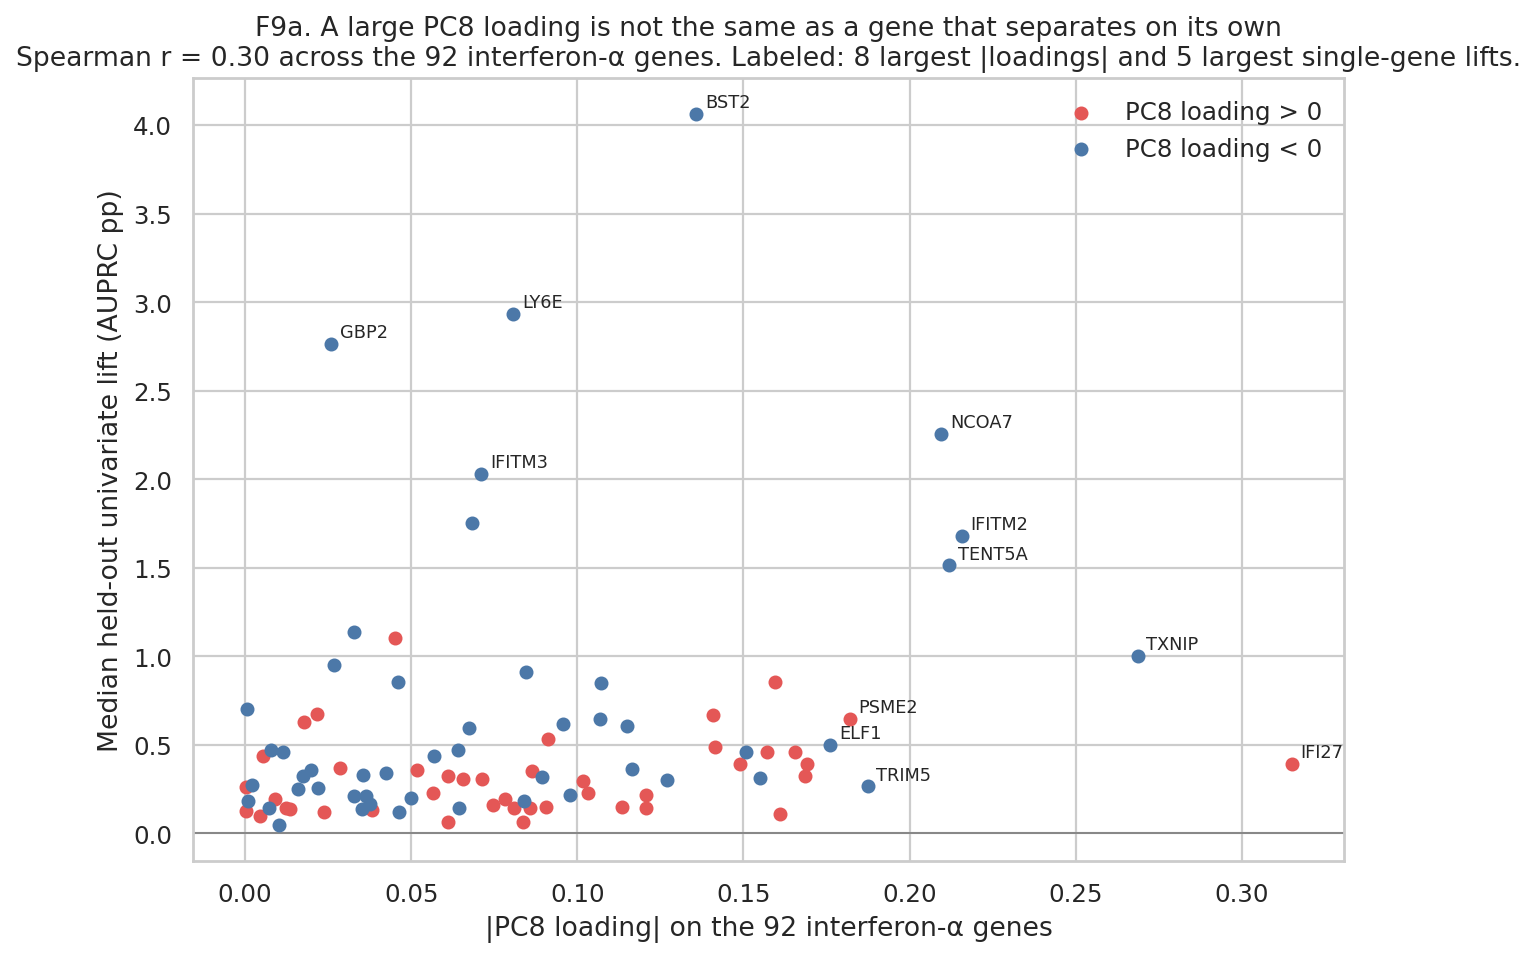

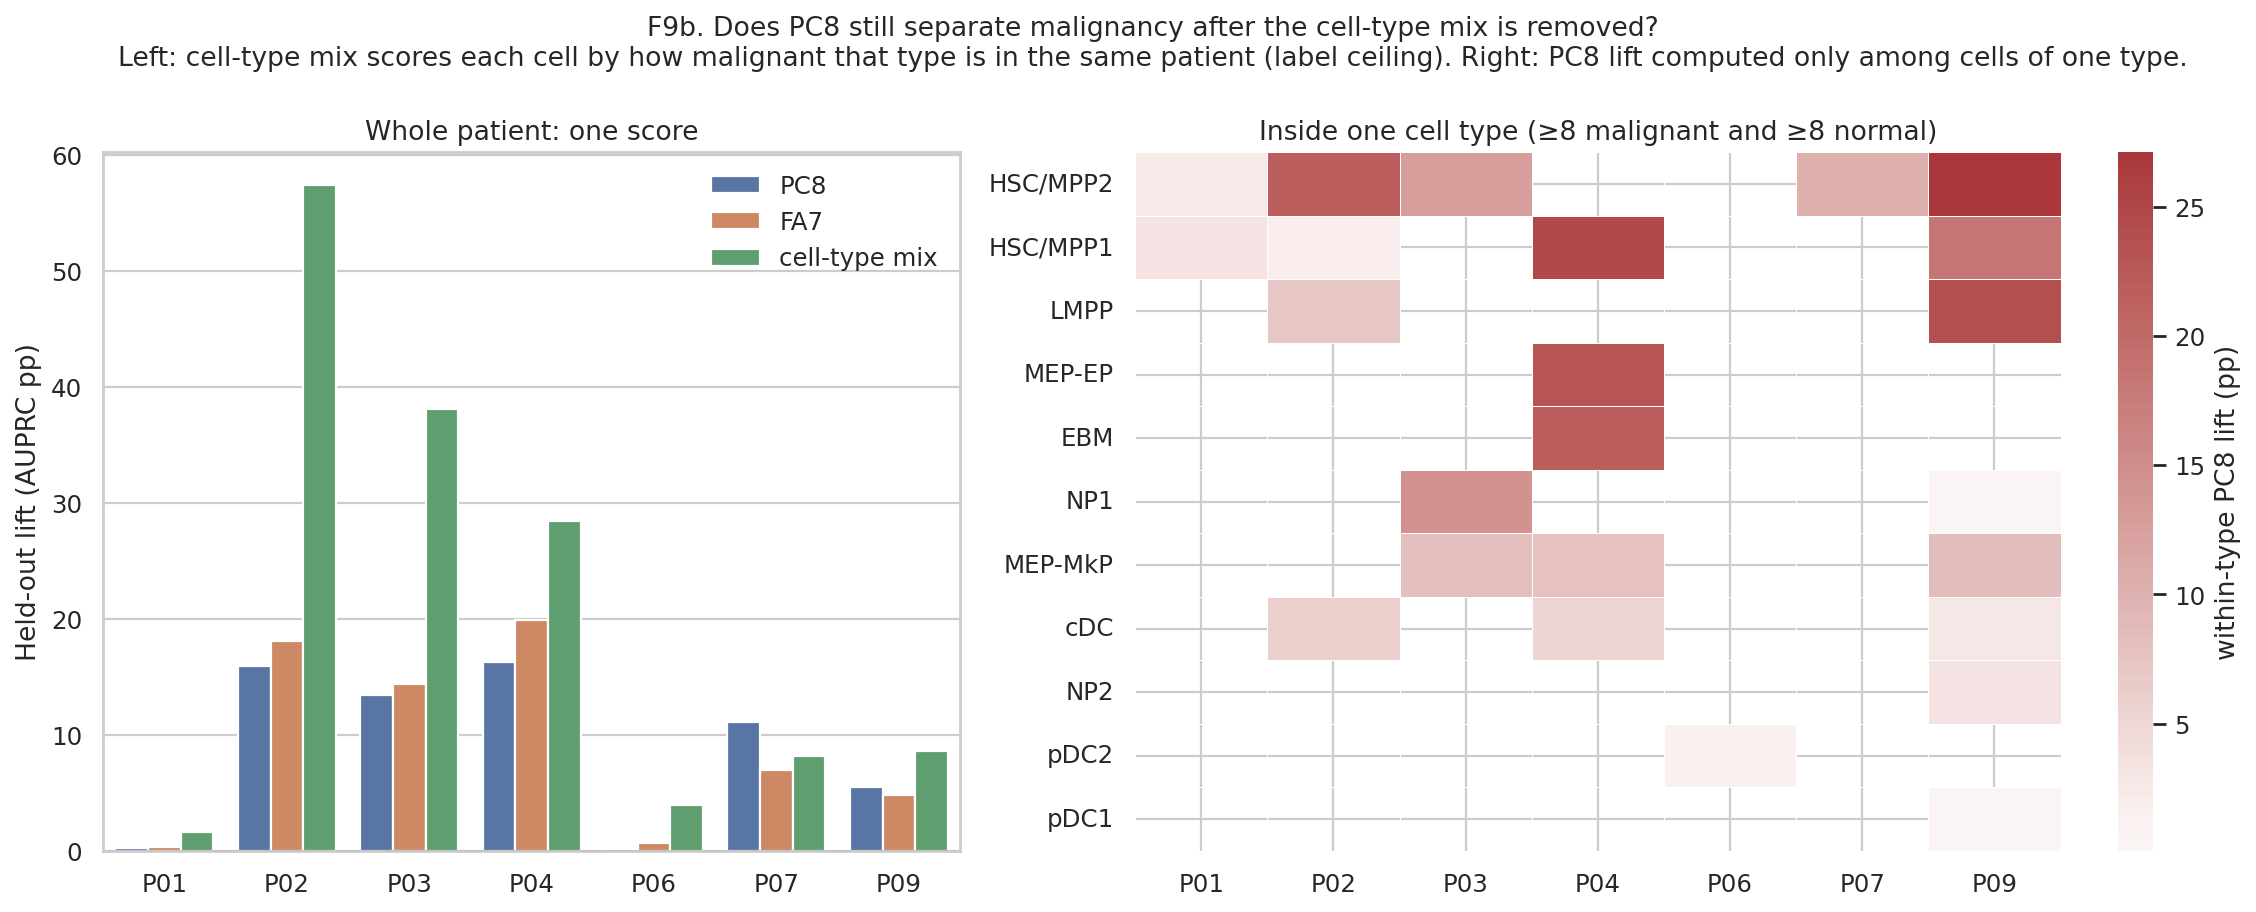

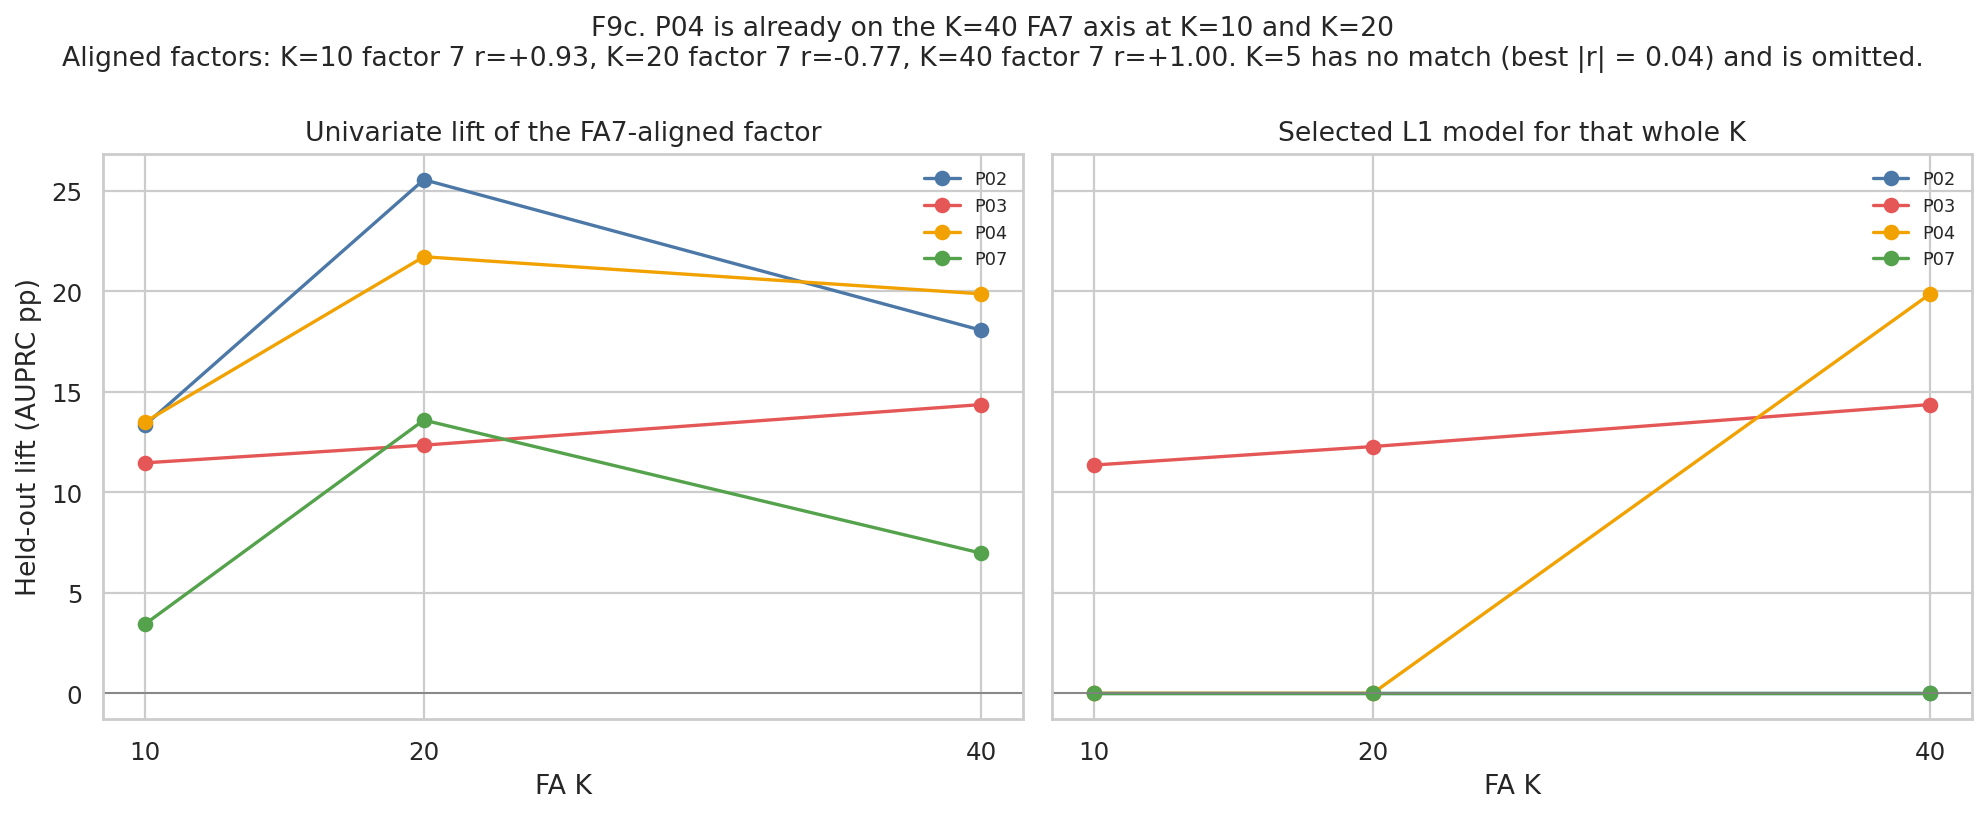

In [9]:
def sign_agnostic_ap(y, score):
    """AUPRC of a score or its flip. A constant score returns the prevalence."""
    y = np.asarray(y)
    score = np.asarray(score, dtype=float)
    if len(y) == 0 or y.sum() == 0 or y.sum() == len(y) or np.nanstd(score) < 1e-12:
        return float(np.mean(y)) if len(y) else np.nan
    return float(max(average_precision_score(y, score), average_precision_score(y, -score)))


pca40 = load_stage1(IFNA_PANEL, "pca", 40)
genes = pca40["genes"]
fa_by_k = {k: load_stage1(IFNA_PANEL, "fa", k) for k in (5, 10, 20, 40)}

cohort = ad.read_h5ad(COHORT_CACHE, backed="r")
obs = cohort.obs
patients = obs["patient"].astype(str).to_numpy()
labels = obs["CN.label"].astype(str).eq("cancer").astype(int).to_numpy()
cell_types = obs["predicted.annotation"].astype(str).to_numpy()
assert np.array_equal(patients, cell_patients)
assert np.array_equal(labels, cell_labels)
present = [gene for gene in genes if gene in cohort.var_names]
missing_genes = [gene for gene in genes if gene not in cohort.var_names]
print("IFN-α genes missing from the cohort cache:", missing_genes)
expression = cohort[:, present].X
if hasattr(expression, "toarray"):
    expression = expression.toarray()
expression = np.asarray(expression, dtype=np.float64)
cohort.file.close()
assert expression.shape == (60_118, len(present))

std = expression.std(axis=0)
std[std < 1e-12] = 1.0
gene_z = (expression - expression.mean(axis=0)) / std
pc8_loading = pd.Series(pca40["loadings"][:, 7], index=genes)

gene_rows = []
for patient in SUPPORTED_PATIENTS:
    mask = patients == patient
    y = labels[mask]
    prevalence = float(y.mean())
    held = gene_z[mask]
    for j, gene in enumerate(present):
        ap = sign_agnostic_ap(y, held[:, j])
        gene_rows.append(
            {
                "heldout_patient": patient,
                "gene": gene,
                "heldout_univariate_auprc": ap,
                "heldout_univariate_lift": ap - prevalence,
                "patient_prevalence": prevalence,
                "pc8_loading": float(pc8_loading[gene]),
            }
        )
gene_patient = pd.DataFrame(gene_rows)
write_csv(gene_patient, "f9_ifna_pc8_loading_vs_gene_univariate.csv")
summary = (
    gene_patient.groupby("gene", as_index=False)
    .agg(
        median_lift=("heldout_univariate_lift", "median"),
        mean_lift=("heldout_univariate_lift", "mean"),
        pc8_loading=("pc8_loading", "first"),
    )
)
summary["abs_loading"] = summary["pc8_loading"].abs()
summary["median_lift_pp"] = 100 * summary["median_lift"]
summary = summary.sort_values("abs_loading", ascending=False)
spearman = float(summary["abs_loading"].corr(summary["median_lift_pp"], method="spearman"))
print(f"Spearman |PC8 loading| vs median single-gene lift: {spearman:.3f}")
write_csv(summary, "f9_ifna_pc8_loading_vs_gene_univariate_summary.csv")
display(summary.head(12).round(3))
display(summary.nlargest(8, "median_lift_pp")[["gene", "pc8_loading", "abs_loading", "median_lift_pp"]].round(3))

fig, ax = plt.subplots(figsize=(8.2, 6.2))
positive = summary["pc8_loading"] >= 0
ax.scatter(summary.loc[positive, "abs_loading"], summary.loc[positive, "median_lift_pp"], s=28, c="#E45756", label="PC8 loading > 0", zorder=3)
ax.scatter(summary.loc[~positive, "abs_loading"], summary.loc[~positive, "median_lift_pp"], s=28, c="#4C78A8", label="PC8 loading < 0", zorder=3)
label_genes = set(summary.head(8)["gene"]) | set(summary.nlargest(5, "median_lift_pp")["gene"])
for _, row in summary.loc[summary["gene"].isin(label_genes)].iterrows():
    ax.annotate(row["gene"], (row["abs_loading"], row["median_lift_pp"]), textcoords="offset points", xytext=(4, 3), fontsize=8)
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("|PC8 loading| on the 92 interferon-α genes")
ax.set_ylabel("Median held-out univariate lift (AUPRC pp)")
ax.set_title(
    "F9a. A large PC8 loading is not the same as a gene that separates on its own\n"
    f"Spearman r = {spearman:.2f} across the 92 interferon-α genes. "
    "Labeled: 8 largest |loadings| and 5 largest single-gene lifts."
)
ax.legend(frameon=False)
fig.tight_layout()
save_figure(fig, "F9a_ifna_pc8_loading_vs_gene_lift")
plt.show()

# F9b. Orient PC8 and FA7 within each patient so malignant cells sit higher, then repeat inside one cell type.
MIN_CLASS = 8
pca8_score = pca40["scores"][:, 7]
fa7_score = fa_by_k[40]["scores"][:, 6]
within_rows = []
patient_rows = []
for patient in SUPPORTED_PATIENTS:
    mask = patients == patient
    y = labels[mask]
    prevalence = float(y.mean())
    pca_s = pca8_score[mask]
    fa_s = fa7_score[mask]
    pca_s = pca_s if pca_s[y == 1].mean() >= pca_s[y == 0].mean() else -pca_s
    fa_s = fa_s if fa_s[y == 1].mean() >= fa_s[y == 0].mean() else -fa_s
    types = cell_types[mask]
    rates = pd.Series(y).groupby(pd.Series(types)).mean()
    ceiling = rates.reindex(types).to_numpy(float)
    patient_rows.append(
        {
            "heldout_patient": patient,
            "n_malignant": int(y.sum()),
            "prevalence": prevalence,
            "pc8_lift_pp": 100 * (average_precision_score(y, pca_s) - prevalence),
            "fa7_lift_pp": 100 * (average_precision_score(y, fa_s) - prevalence),
            "celltype_ceiling_lift_pp": 100 * (average_precision_score(y, ceiling) - prevalence),
        }
    )
    for ctype in pd.unique(types):
        idx = np.flatnonzero(types == ctype)
        y_sub = y[idx]
        n_mal = int(y_sub.sum())
        n_norm = int(len(y_sub) - n_mal)
        if n_mal < MIN_CLASS or n_norm < MIN_CLASS:
            continue
        prev_sub = float(y_sub.mean())
        within_rows.append(
            {
                "heldout_patient": patient,
                "predicted_annotation": ctype,
                "n_cells": int(len(y_sub)),
                "n_malignant": n_mal,
                "n_normal": n_norm,
                "within_prevalence": prev_sub,
                "pc8_within_lift_pp": 100 * (average_precision_score(y_sub, pca_s[idx]) - prev_sub),
                "fa7_within_lift_pp": 100 * (average_precision_score(y_sub, fa_s[idx]) - prev_sub),
                "pc8_mean_gap": float(pca_s[idx][y_sub == 1].mean() - pca_s[idx][y_sub == 0].mean()),
            }
        )
patient_df = pd.DataFrame(patient_rows)
within_df = pd.DataFrame(within_rows)
write_csv(patient_df, "f9_ifna_pc8_vs_celltype_ceiling.csv")
write_csv(within_df, "f9_ifna_pc8_within_celltype_lift.csv")
display(patient_df.round(2))
display(within_df.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14.6, 5.8), gridspec_kw={"width_ratios": [1, 1.35]})
plot_p = patient_df.melt(
    id_vars="heldout_patient",
    value_vars=["pc8_lift_pp", "fa7_lift_pp", "celltype_ceiling_lift_pp"],
    var_name="score",
    value_name="lift_pp",
)
plot_p["score"] = plot_p["score"].map(
    {"pc8_lift_pp": "PC8", "fa7_lift_pp": "FA7", "celltype_ceiling_lift_pp": "cell-type mix"}
)
sns.barplot(
    data=plot_p, x="heldout_patient", y="lift_pp", hue="score",
    hue_order=["PC8", "FA7", "cell-type mix"], order=SUPPORTED_PATIENTS, ax=axes[0], errorbar=None,
)
axes[0].axhline(0, color="0.4", lw=0.8)
axes[0].set_ylabel("Held-out lift (AUPRC pp)")
axes[0].set_xlabel("")
axes[0].set_title("Whole patient: one score")
axes[0].legend(frameon=False, title="")
heat = within_df.pivot(index="predicted_annotation", columns="heldout_patient", values="pc8_within_lift_pp")
heat = heat.reindex(columns=[p for p in SUPPORTED_PATIENTS if p in heat.columns])
heat = heat.loc[heat.abs().max(axis=1).sort_values(ascending=False).index]
sns.heatmap(heat, cmap="vlag", center=0, ax=axes[1], linewidths=0.3, linecolor="white", cbar_kws={"label": "within-type PC8 lift (pp)"})
axes[1].set_title(f"Inside one cell type (≥{MIN_CLASS} malignant and ≥{MIN_CLASS} normal)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
fig.suptitle(
    "F9b. Does PC8 still separate malignancy after the cell-type mix is removed?\n"
    "Left: cell-type mix scores each cell by how malignant that type is in the same patient (label ceiling). "
    "Right: PC8 lift computed only among cells of one type.",
    fontsize=12,
)
fig.tight_layout()
save_figure(fig, "F9b_ifna_pc8_within_celltype")
plt.show()

# F9c. Independent K fits. Keep a match only when |score correlation| with K=40 FA7 is at least 0.5.
fa7_40 = fa_by_k[40]["scores"][:, 6]
fa7_40_z = (fa7_40 - fa7_40.mean()) / fa7_40.std()
match_rows = []
lift_rows = []
for k, art in fa_by_k.items():
    scores = art["scores"]
    scale = np.where(scores.std(axis=0) > 1e-12, scores.std(axis=0), 1.0)
    scores_z = (scores - scores.mean(axis=0)) / scale
    corr = (scores_z.T @ fa7_40_z) / len(fa7_40_z)
    order = np.argsort(-np.abs(corr))
    best, second = int(order[0]), int(order[1])
    match_rows.append(
        {
            "k": k,
            "best_factor": best + 1,
            "best_r_with_fa40_factor7": float(corr[best]),
            "second_factor": second + 1,
            "second_r": float(corr[second]),
        }
    )
    for patient in SUPPORTED_PATIENTS:
        mask = patients == patient
        y = labels[mask]
        prevalence = float(y.mean())
        ap = sign_agnostic_ap(y, scores[mask, best])
        lift_rows.append(
            {
                "k": k,
                "matched_factor": best + 1,
                "r_with_fa40_factor7": float(corr[best]),
                "heldout_patient": patient,
                "univariate_lift_pp": 100 * (ap - prevalence),
            }
        )
match_df = pd.DataFrame(match_rows)
lift_df = pd.DataFrame(lift_rows)
selected = atlas_patient.loc[
    atlas_patient["stage0_panel_id"].eq(IFNA_PANEL) & atlas_patient["configuration"].str.startswith("fa|K=")
].copy()
selected["k"] = selected["configuration"].str.replace("fa|K=", "", regex=False).astype(int)
selected["selected_model_lift_pp"] = 100 * selected["heldout_lift"]
lift_df = lift_df.merge(selected[["k", "heldout_patient", "selected_model_lift_pp"]], on=["k", "heldout_patient"], how="left")
write_csv(match_df, "f9_ifna_fa_k_match_to_fa40_factor7.csv")
write_csv(lift_df, "f9_ifna_fa_matched_factor_lift_by_k.csv")
display(match_df.round(3))
display(lift_df.round(2))

aligned = lift_df.loc[lift_df["r_with_fa40_factor7"].abs() >= 0.5].copy()
fig, axes = plt.subplots(1, 2, figsize=(12.6, 5.2), sharey=True)
colors = {"P02": "#4C78A8", "P03": "#E45756", "P04": "#F2A200", "P07": "#54A24B"}
for ax, column, title in [
    (axes[0], "univariate_lift_pp", "Univariate lift of the FA7-aligned factor"),
    (axes[1], "selected_model_lift_pp", "Selected L1 model for that whole K"),
]:
    for patient, color in colors.items():
        sub = aligned.loc[aligned["heldout_patient"].eq(patient)].sort_values("k")
        ax.plot(sub["k"], sub[column], marker="o", color=color, label=patient)
    ax.set_xticks([10, 20, 40])
    ax.set_xlabel("FA K")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Held-out lift (AUPRC pp)")
match_note = ", ".join(
    f"K={int(row.k)} factor {int(row.best_factor)} r={row.best_r_with_fa40_factor7:+.2f}"
    for row in match_df.itertuples()
    if abs(row.best_r_with_fa40_factor7) >= 0.5
)
fig.suptitle(
    "F9c. P04 is already on the K=40 FA7 axis at K=10 and K=20\n"
    f"Aligned factors: {match_note}. K=5 has no match (best |r| = 0.04) and is omitted.",
    fontsize=12,
)
fig.tight_layout()
save_figure(fig, "F9c_ifna_fa_matched_factor_across_k")
plt.show()


### How to read F9

**F9a.** The x-axis is how hard PC8 leans on a gene. The y-axis is that gene's own median held-out lift, in AUPRC percentage points, across the seven patients. A gene in the top-right would be both heavily used by PC8 and predictive alone. IFI27 is the largest loading (+0.31) and only +0.4 pp alone. BST2, LY6E, and GBP2 are the strongest single genes (about +4, +3, and +2.8 pp) and sit at modest loadings. Spearman r is 0.30. PC8 is a combination, not a re-ranking of the best single interferon genes. The positive end of the loading (IFI27, PSME2, PSMA3) and the negative end (TXNIP, IFITM2, TENT5A) are a contrast inside the 92-gene panel. IFI27 and IFITM2 are both interferon-stimulated and they load on opposite sides.

**F9b, left.** Blue is PC8, orange is FA7, green is the cell-type mix ceiling. In P02 and P03 the green bar is much taller (about +57 and +38 pp) than PC8 (about +16 and +13 pp). Malignant cells are concentrated in a few predicted types, and that concentration alone outruns PC8. In P07 the order flips: PC8 is about +11 pp and the cell-type ceiling is about +8 pp, on only 22 malignant cells.

**F9b, right.** Each square is PC8's lift computed only inside one cell type, using the direction that points toward malignant cells in that patient. Blank means the type did not have at least 8 malignant and 8 normal cells. HSC/MPP2 stays positive in P02 (+22 pp, 45 vs 44 cells), P03 (+13 pp, 438 vs 170), P07 (+10 pp), and P09 (+27 pp). P04's mixed compartments are positive too: HSC/MPP1 +25 pp, MEP-EP +23 pp. So PC8 is not only a proxy for "this cell is an HSC." Inside P03's NP1 compartment, PC8 is +14 pp and the patient-oriented FA7 score is −3.5 pp. The two factors are related across all cells and not interchangeable inside every compartment.

**F9c, left.** The factor in the K=10 fit that matches K=40 FA7 is factor 7, r = +0.93. At K=20 it is again factor 7, r = −0.77, a sign flip of the same axis. On that axis, P04's univariate lift is already +13.5 pp at K=10 and +21.7 pp at K=20. P02 is on it as well (+13 to +26 pp). K=5 has no factor correlated with FA7.

**F9c, right.** The selected L1 model, at the same C, keeps only P03 at K=10 and K=20. P04's curve jumps from 0 to +20 pp at K=40. P02 stays at 0 even at K=40, despite +18 pp of univariate FA7 lift. P04's arrival is the L1 model starting to keep a patient who was already on this axis, not a new direction appearing among the later factors.

The inductive refit, PCA and FA learned without the held-out patient, is still not in this notebook.


In [27]:
ledger = pd.DataFrame(
    {
        "path": [str(path.relative_to(EXP_DIR)) for path in GENERATED_TABLES + GENERATED_FIGURES],
        "kind": ["table"] * len(GENERATED_TABLES) + ["figure"] * len(GENERATED_FIGURES),
    }
)
write_csv(ledger, "f_artifact_ledger.csv")
print(f"{len(GENERATED_FIGURES)} figure files, {len(GENERATED_TABLES)} tables")


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/feedback_deep_dive_20260917/f_artifact_ledger.csv
58 figure files, 30 tables
